# Clasificación de sonidos ambientales de ESC-50 con el Audio Spectrogram Transformer (AST)

**Miniproyecto 4 · Técnicas de Deep Learning (MAIA-4213) · Maestría en Inteligencia Artificial, Universidad de los Andes**

**Autores:** Miguel Muñoz, David Cardenas y Mario Celis

**Objetivo (enunciado):** hacer *fine-tuning* durante **2 épocas** y evaluar el modelo preentrenado Audio Spectrogram Transformer (AST) para clasificar sonidos ambientales a partir de sus espectrogramas.

**Datos:** ESC-50 [1], cargado desde Hugging Face como indica el enunciado (`load_dataset("confit/esc50-demo", "fold1", ...)`). **Modelo:** `MIT/ast-finetuned-audioset-10-10-0.4593` [2].

Las convenciones de la versión 1 se mantienen: 50 clases agrupadas en las 5 categorías de ESC-50, el split `test` del fold 1 reservado como **prueba**, y una **validación** sin fuga de grabaciones (la misma partición de la v1, para que las dos versiones sean comparables).

### Qué cambia respecto a la versión 1

| Cambio | Motivo | ¿Cómo se valida? |
|---|---|---|
| **Entrada de 512 tramas** (5,12 s) en lugar de 1 024 | Los clips duran 5 s (≈ 500 tramas): con 1 024, la mitad de la entrada es relleno. Es la longitud que usa el artículo de AST para ESC-50 [2]. Pasa de 1 212 a 600 parches: ≈ 2× más rápido y menos memoria en el M2 | Todas las corridas v2 la usan; se compara con la v1 al final |
| **Cabeza inicializada desde AudioSet** | AST ya tiene neuronas de salida para "Dog", "Rain", "Chainsaw", etc. Cada clase de ESC-50 parte de los pesos de sus clases equivalentes de AudioSet en lugar de valores aleatorios: con solo 2 épocas, el punto de partida importa | Evaluación *zero-shot* (sin entrenar) y ablación en validación |
| **Tasas de aprendizaje por capa (LLRD)** | Las capas bajas guardan rasgos generales y se ajustan menos; las altas, más específicas, se ajustan más [12] | Ablación en validación |
| **SpecAugment según la receta de AST** (1 máscara de frecuencia ≤ 24 y 1 de tiempo ≤ 96) | Con 512 tramas, las máscaras caen sobre audio real y no sobre relleno | Ablación en validación |
| **Sin *weight decay* en sesgos, LayerNorm ni *embeddings* de posición** | Práctica estándar en transformers | Parte de la receta base v2 |
| **Ensamble de 3 semillas** | Promediar probabilidades de modelos con distinta semilla reduce la varianza; cada modelo se entrena 2 épocas | Se reporta modelo individual (media ± std) y ensamble |
| **Ajustes para Apple Silicon (M2, MPS)** | Atención SDPA, lote según la RAM, *fallback* de MPS, sin `autocast` en MPS por defecto | Celda de configuración |

**Metodología (skill `DL_Agent`):** enunciado → análisis → diseño → implementación → entrenamiento → evaluación → documentación → validación final. Cada cambio se acepta **solo si mejora el F1-macro de validación**; la prueba no se usa para decidir nada. Todas las cifras provienen de las salidas de este notebook.

| # | Actividad del enunciado | Sección |
|---|---|---|
| 1 | Pipeline de audio a espectrogramas normalizados y de tamaño consistente, listos para AST | 1 y 2 |
| 2 | *Fine-tuning* de AST durante 2 épocas | 5 a 9 |
| 3 | Precision, recall y F1; mejores y peores categorías; matriz de confusión y categorías más confundidas | 10 y 11 |

## Entorno (se ejecuta primero)

Verifica que el kernel tenga las dependencias de `requirements.txt` y, si falta alguna, la instala en ese mismo kernel. Luego confirma si la GPU de Apple (MPS) está disponible.

In [21]:
import sys, subprocess, importlib.util
from pathlib import Path
_req = next(p / "requirements.txt" for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
_need = {"torch": "torch", "transformers": "transformers", "datasets": "datasets", "soundfile": "soundfile", "sklearn": "scikit-learn",
         "scipy": "scipy", "pandas": "pandas", "matplotlib": "matplotlib", "tqdm": "tqdm", "ipywidgets": "ipywidgets"}
_missing = [pkg for mod, pkg in _need.items() if importlib.util.find_spec(mod) is None]
print("Python del kernel:", sys.executable)
if _missing:
    print("Instalando dependencias faltantes:", _missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-r", str(_req)])
    print("Listo. Si algo falla al importar, reinicie el kernel y vuelva a ejecutar.")
else:
    print("Todas las dependencias están instaladas.")
import torch
print("torch", torch.__version__, "| MPS disponible:", torch.backends.mps.is_available())

Python del kernel: /Users/davidcardenas/Documents/MAIA/ML/JupyterProjects/.venv/bin/python
Todas las dependencias están instaladas.
torch 2.13.0 | MPS disponible: True


## 0. Configuración (incluye ajustes para MacBook M2)

- **Dispositivo:** se usa la GPU de Apple (`mps`) si está disponible. `PYTORCH_ENABLE_MPS_FALLBACK=1` se fija **antes** de importar `torch`, para que una operación no implementada en MPS se ejecute en CPU en lugar de detener el entrenamiento.
- **Memoria:** el M2 comparte la RAM entre CPU y GPU. Se lee la RAM del equipo: con ≤ 8 GB se usa lote 4 × 4 de acumulación y *gradient checkpointing*; con más, lote 8 × 2. El lote efectivo es 16 en ambos casos.
- **Precisión:** fp32 en MPS (por defecto). `amp_mps=True` activa fp16 experimental: más rápido pero sin escalado de gradientes, así que puede ser inestable.
- **Atención SDPA** (`scaled_dot_product_attention`), más eficiente en memoria que la implementación explícita.
- Igual que en la v1: espectrogramas calculados una vez en `data/cache/`, resultados de cada corrida guardados (si existen, se cargan en lugar de reentrenar), `num_workers=0` (evita problemas de multiproceso de Jupyter en macOS) y audio leído con `soundfile` + `scipy` (sin FFmpeg ni `torchcodec`).
- Las salidas de la v2 van a `outputs/v2/` para no sobrescribir las de la v1.

**Si aparece `MPS backend out of memory`:** reduzca `batch_size` a 4 con `grad_accum=4`, active `grad_checkpointing=True` y cierre otras aplicaciones.

In [22]:
import os
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")   # debe fijarse antes de importar torch
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

import io, re, gc, copy, json, math, time, random, platform, warnings, contextlib, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
from scipy.signal import resample_poly
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import transformers
from transformers import ASTFeatureExtractor, ASTForAudioClassification, ASTConfig, get_linear_schedule_with_warmup
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, f1_score, confusion_matrix
from sklearn.manifold import TSNE
from scipy.fft import dct

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="torch")
transformers.logging.set_verbosity_error()
plt.style.use("default")   # estilo claro e independiente del tema del editor (figuras aptas para el informe IEEE)
plt.rcParams.update({"axes.grid": False, "figure.facecolor": "white", "savefig.facecolor": "white"})

ROOT = Path.cwd().resolve()
while not (ROOT / "README.md").exists() or not (ROOT / "notebooks").exists():
    if ROOT == ROOT.parent:
        raise RuntimeError("Abra el notebook desde el repositorio esc50-ast-sound-classifier.")
    ROOT = ROOT.parent

QUICK = os.environ.get("MP4_QUICK", "0") == "1"   # prueba de humo sin internet: audio sintético y AST diminuto
RETRAIN = False                                   # True: reentrena aunque existan resultados guardados
SAVE_MODEL = False                                # True: guarda los pesos del modelo final (≈ 350 MB)

OUT = ROOT / "outputs" / ("_smoke_test_v2" if QUICK else "v2")
TAB, FIG, MODELS, RUNS = OUT / "tables", OUT / "figures", OUT / "models", OUT / "tables" / "runs"
SPLITS = ROOT / "data" / ("splits_smoke" if QUICK else "splits")          # misma partición que la v1
REPORT_FIGS = (OUT / "report_figs") if QUICK else (ROOT / "report" / "figs")

CONFIG = dict(
    dataset="confit/esc50-demo", dataset_config="fold1",
    model="MIT/ast-finetuned-audioset-10-10-0.4593",
    sampling_rate=16_000,       # AST fue preentrenado con audio a 16 kHz
    max_length=512,             # v2: 512 tramas (5,12 s) como la receta de AST para ESC-50 [2]; la v1 usaba 1 024
    epochs=2,                   # fijado por el enunciado
    batch_size=8, grad_accum=2, # lote efectivo de 16
    lr_backbone=3e-5,           # tasa única del transformer (receta sin LLRD, igual a la v1)
    lr_head=1e-3,               # la cabeza nueva necesita una tasa mayor
    llrd=dict(lr_top=1e-4, decay=0.75),   # LLRD: capa 12 → 1e-4, capa 1 → 1e-4·0,75^11 ≈ 4e-6, embeddings ≈ 3e-6
    weight_decay=0.01, warmup=0.1, clip=1.0,
    specaug=dict(freq_masks=1, freq_width=24, time_masks=1, time_width=96),  # receta de AST para ESC-50 [2]
    val_folds=5,                # 1/5 de los grupos de entrenamiento va a validación (igual que la v1)
    grad_checkpointing=False,
    amp_mps=False,              # fp16 experimental en MPS
    seed=42, seeds=[42, 7, 123],
)
if QUICK:
    CONFIG.update(epochs=1, batch_size=16, grad_accum=1, seeds=[42, 7])

def ram_gb():
    try:
        if platform.system() == "Darwin":
            return int(subprocess.check_output(["sysctl", "-n", "hw.memsize"]).strip()) / 2**30
        return os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 2**30
    except Exception:
        return None

DEVICE = torch.device("cuda" if torch.cuda.is_available() else
                      "mps" if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available() else "cpu")
RAM = ram_gb()
if DEVICE.type == "mps" and not QUICK and RAM is not None and RAM <= 8.5:
    CONFIG.update(batch_size=4, grad_accum=4, grad_checkpointing=True)   # M2 de 8 GB: mismo lote efectivo, menos memoria

AMP_DTYPE = torch.float16 if DEVICE.type == "cuda" or (DEVICE.type == "mps" and CONFIG["amp_mps"]) else None
USE_SCALER = DEVICE.type == "cuda"
def amp_ctx():
    # autocast solo cuando hay precisión mixta; en otro caso un contexto vacío (evita errores de autocast en MPS antiguos)
    return torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE) if AMP_DTYPE is not None else contextlib.nullcontext()

def empty_cache():
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    elif DEVICE.type == "mps":
        torch.mps.empty_cache()

def set_seed(seed: int) -> None:
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

for d in [TAB, FIG, MODELS, RUNS, SPLITS, REPORT_FIGS]:
    d.mkdir(parents=True, exist_ok=True)
set_seed(CONFIG["seed"])
chip = platform.processor() or platform.machine()
if platform.system() == "Darwin":
    try:
        chip = subprocess.check_output(["sysctl", "-n", "machdep.cpu.brand_string"]).decode().strip()
    except Exception:
        pass
gpu = torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else (f"Apple GPU (MPS) · {chip}" if DEVICE.type == "mps" else f"CPU · {chip}")
print(f"Python {platform.python_version()} | torch {torch.__version__} | transformers {transformers.__version__} | macOS/OS {platform.platform()}")
print(f"Dispositivo: {DEVICE} ({gpu}) | RAM: {RAM:.0f} GB | precisión: {AMP_DTYPE or 'fp32'} | modo rápido: {QUICK}" if RAM else f"Dispositivo: {DEVICE} ({gpu})")
if DEVICE.type == "cpu" and not QUICK:
    print("ADVERTENCIA: sin GPU (CUDA o MPS) el fine-tuning de AST tarda varias horas.")
print(json.dumps(CONFIG, indent=1))

Python 3.14.2 | torch 2.13.0 | transformers 5.23.0 | macOS/OS macOS-26.3.1-arm64-arm-64bit-Mach-O
Dispositivo: mps (Apple GPU (MPS) · Apple M2 Pro) | RAM: 16 GB | precisión: fp32 | modo rápido: False
{
 "dataset": "confit/esc50-demo",
 "dataset_config": "fold1",
 "model": "MIT/ast-finetuned-audioset-10-10-0.4593",
 "sampling_rate": 16000,
 "max_length": 512,
 "epochs": 2,
 "batch_size": 8,
 "grad_accum": 2,
 "lr_backbone": 3e-05,
 "lr_head": 0.001,
 "llrd": {
  "lr_top": 0.0001,
  "decay": 0.75
 },
 "weight_decay": 0.01,
 "warmup": 0.1,
 "clip": 1.0,
 "specaug": {
  "freq_masks": 1,
  "freq_width": 24,
  "time_masks": 1,
  "time_width": 96
 },
 "val_folds": 5,
 "grad_checkpointing": false,
 "amp_mps": false,
 "seed": 42,
 "seeds": [
  42,
  7,
  123
 ]
}


## 1. Carga y exploración de los datos

Igual que en la v1: se carga el fold 1 de ESC-50 con el código del enunciado, los WAV (44,1 kHz) se leen sin decodificar (`Audio(decode=False)`) y `load_audio` los convierte a mono y los **remuestrea a 16 kHz**. Las 50 clases se agrupan en las 5 categorías oficiales [1].

In [23]:
CATEGORIAS = {
    "Animales": ["dog", "rooster", "pig", "cow", "frog", "cat", "hen", "insects", "sheep", "crow"],
    "Naturales y agua": ["rain", "sea_waves", "crackling_fire", "crickets", "chirping_birds", "water_drops", "wind",
                         "pouring_water", "toilet_flush", "thunderstorm"],
    "Humanos no verbales": ["crying_baby", "sneezing", "clapping", "breathing", "coughing", "footsteps", "laughing",
                            "brushing_teeth", "snoring", "drinking_sipping"],
    "Domésticos": ["door_wood_knock", "mouse_click", "keyboard_typing", "door_wood_creaks", "can_opening",
                   "washing_machine", "vacuum_cleaner", "clock_alarm", "clock_tick", "glass_breaking"],
    "Urbanos": ["helicopter", "chainsaw", "siren", "car_horn", "engine", "train", "church_bells", "airplane",
                "fireworks", "hand_saw"],
}
CLASE2CAT = {c: cat for cat, cs in CATEGORIAS.items() for c in cs}
norm_name = lambda s: re.sub(r"[\s\-]+", "_", str(s).strip().lower())

def synthetic_esc50(n_train_per_class=6, n_test_per_class=2, seconds=5.0, sr=44_100, seed=0):
    # Solo para la prueba de humo: tonos con frecuencia propia por clase + ruido, guardados como WAV de 44,1 kHz
    rng = np.random.default_rng(seed); classes = [c for cs in CATEGORIAS.values() for c in cs]; rows = {"train": [], "test": []}
    t = np.arange(int(seconds * sr)) / sr
    for k, c in enumerate(classes):
        for split, n, folds in [("train", n_train_per_class, [2, 3, 4, 5]), ("test", n_test_per_class, [1])]:
            for j in range(n):
                f0 = 150 + 60 * k
                wav = 0.3 * np.sin(2 * np.pi * f0 * t) + 0.05 * rng.standard_normal(t.size)
                src = f"{k:02d}{j // 2:03d}{int(split == 'test')}"
                buf = io.BytesIO(); sf.write(buf, wav.astype(np.float32), sr, format="WAV", subtype="PCM_16")
                rows[split].append({"audio": {"bytes": buf.getvalue(), "path": f"{folds[j % len(folds)]}-{src}-{'AB'[j % 2]}-{k}.wav"},
                                    "target": k, "category": c, "fold": folds[j % len(folds)]})
    return rows["train"], rows["test"]

if QUICK:
    train_ds, test_ds = synthetic_esc50()
    columns = list(train_ds[0].keys())
else:
    from datasets import load_dataset, Audio
    train_ds = load_dataset(CONFIG["dataset"], CONFIG["dataset_config"], split="train")
    test_ds = load_dataset(CONFIG["dataset"], CONFIG["dataset_config"], split="test")
    print(train_ds)
    columns = train_ds.column_names
    audio_col = next(c for c in columns if c.lower() in ("audio", "wav", "sound"))
    train_ds = train_ds.cast_column(audio_col, Audio(decode=False))
    test_ds = test_ds.cast_column(audio_col, Audio(decode=False))

def load_audio(a, target_sr=CONFIG["sampling_rate"]):
    # Devuelve (forma de onda mono float32, frecuencia) a target_sr, para audio ya decodificado o bytes / ruta de un WAV
    if isinstance(a, dict) and a.get("array") is not None:
        x, sr = np.asarray(a["array"], dtype=np.float32), int(a["sampling_rate"])
        x = x.mean(axis=0) if x.ndim > 1 else x
    elif isinstance(a, dict):
        x, sr = sf.read(io.BytesIO(a["bytes"]) if a.get("bytes") else a["path"], dtype="float32", always_2d=True)
        x = x.mean(axis=1)
    else:                                   # AudioDecoder de torchcodec (datasets >= 4 con decode=True)
        smp = a.get_all_samples(); x, sr = smp.data.numpy().mean(axis=0), int(smp.sample_rate)
    if target_sr and sr != target_sr:
        g = math.gcd(sr, target_sr); x = resample_poly(x, target_sr // g, sr // g)
    return np.ascontiguousarray(x, dtype=np.float32), (target_sr or sr)

def describe_columns(columns, sample):
    pick = lambda opts: next((c for c in columns if c.lower() in opts), None)
    return dict(audio=pick(("audio", "wav", "sound")), label=pick(("target", "label", "labels", "class_id")),
                name=pick(("category", "class", "class_name", "label_name", "sound")), fold=pick(("fold",)),
                src=pick(("src_file", "source", "source_file")), filename=pick(("filename", "file", "path")))
COLS = describe_columns(columns, train_ds[0])
print("Columnas:", columns, "\nAsignación:", COLS)
assert COLS["audio"] and (COLS["label"] or COLS["name"]), "Ajuste COLS: no se encontró la columna de audio o de etiqueta"

Dataset({
    features: ['audio', 'sound', 'label'],
    num_rows: 1600
})
Columnas: ['audio', 'sound', 'label'] 
Asignación: {'audio': 'audio', 'label': 'label', 'name': 'sound', 'fold': None, 'src': None, 'filename': None}


In [24]:
def audio_info(a):
    if isinstance(a, dict) and a.get("array") is None:
        inf = sf.info(io.BytesIO(a["bytes"]) if a.get("bytes") else a["path"])
        return dict(duracion_s=inf.duration, sr_original=inf.samplerate, canales=inf.channels)
    x, sr = load_audio(a, target_sr=None) if not isinstance(a, dict) else (np.asarray(a["array"]), a["sampling_rate"])
    return dict(duracion_s=x.shape[-1] / sr, sr_original=sr, canales=1 if x.ndim == 1 else x.shape[0])

def build_metadata(ds, split):
    names = None
    if not QUICK and COLS["label"] and hasattr(ds.features[COLS["label"]], "names"):
        names = ds.features[COLS["label"]].names
    rows = []
    for i, ex in enumerate(tqdm(ds, total=len(ds), desc=f"metadatos {split}")):   # iteración secuencial: mucho más rápida que ds[i]
        a = ex[COLS["audio"]]
        fname = ex.get(COLS["filename"]) if COLS["filename"] else None
        fname = fname or (a.get("path") if isinstance(a, dict) else None) or ""
        fname = os.path.basename(str(fname))
        m = re.match(r"(\d+)-(\w+)-([A-Z])-(\d+)\.wav$", fname)       # formato oficial: {fold}-{src}-{take}-{target}.wav
        name = ex[COLS["name"]] if COLS["name"] else (names[ex[COLS["label"]]] if names else None)
        label = ex[COLS["label"]] if COLS["label"] else None
        rows.append(dict(idx=i, split_hf=split, archivo=fname, clase=norm_name(name) if name is not None else str(label),
                         label_orig=label, fold=ex[COLS["fold"]] if COLS["fold"] else (int(m.group(1)) if m else None),
                         src=ex[COLS["src"]] if COLS["src"] else (m.group(2) if m else f"{split}_{i}"),
                         **audio_info(a)))
    return pd.DataFrame(rows)

t0 = time.time()
meta = pd.concat([build_metadata(train_ds, "train"), build_metadata(test_ds, "test")], ignore_index=True)
CLASSES = sorted(meta.clase.unique(), key=lambda c: (list(CATEGORIAS).index(CLASE2CAT.get(c, "Urbanos")), c))
C2I = {c: i for i, c in enumerate(CLASSES)}
meta["label"] = meta.clase.map(C2I); meta["categoria"] = meta.clase.map(CLASE2CAT)
sin_cat = sorted(set(meta.clase[meta.categoria.isna()]))
print(f"Clips: {len(meta)} | clases: {len(CLASSES)} | metadatos en {time.time() - t0:.0f} s")
print("Clases sin categoría conocida (revisar nombres):", sin_cat or "ninguna")
display(meta.groupby("split_hf").agg(clips=("idx", "size"), clases=("clase", "nunique"), folds=("fold", lambda s: sorted(s.dropna().unique())),
                                     grabaciones=("src", "nunique"), duracion_s_min=("duracion_s", "min"),
                                     duracion_s_max=("duracion_s", "max"), sr_original=("sr_original", "first"), canales=("canales", "max")))
display(pd.crosstab(meta.categoria, meta.split_hf).assign(clases=meta.groupby("categoria").clase.nunique()))

metadatos train:   0%|          | 0/1600 [00:00<?, ?it/s]

metadatos test:   0%|          | 0/400 [00:00<?, ?it/s]

Clips: 2000 | clases: 50 | metadatos en 0 s
Clases sin categoría conocida (revisar nombres): ninguna


,clips,clases,folds,grabaciones,duracion_s_min,duracion_s_max,sr_original,canales
split_hf,,,,,,,,
test,400,50,[1],311,5.0,5.0,44100,1
train,1600,50,"[2, 3, 4, 5]",1213,5.0,5.0,44100,1


split_hf,test,train,clases
categoria,,,
Animales,80,320,10
Domésticos,80,320,10
Humanos no verbales,80,320,10
Naturales y agua,80,320,10
Urbanos,80,320,10


## 2. Pipeline de audio a espectrogramas

Cada clip pasa por el `ASTFeatureExtractor` del modelo preentrenado [2]:

1. **Audio mono a 16 kHz** (remuestreado al cargar).
2. **Banco de filtros log-mel** de 128 bandas al estilo Kaldi: ventanas de 25 ms cada 10 ms (100 tramas por segundo).
3. **Tamaño fijo de 512 tramas** (5,12 s; **cambio v2**). Un clip de 5 s produce ≈ 498 tramas, así que solo se rellenan ≈ 14 (≈ 3 %), frente a ≈ 51 % de relleno con las 1 024 tramas de la v1. El relleno no aporta información y la auto-atención lo procesa igual, con un costo cuadrático en el número de parches. Como AST se preentrenó con 1 024 tramas, sus *embeddings* de posición se adaptan a la nueva longitud (sección 5), igual que en el código original de AST para ESC-50 [2].
4. **Normalización** con la media (−4,27) y el doble de la desviación estándar (4,57) de AudioSet, las mismas del preentrenamiento.

Resultado: una "imagen" de 512 × 128 por clip, guardada en `data/cache/esc50_L512/` como `float16`.

In [25]:
CACHE = ROOT / "data" / "cache" / (f"smoke_L{CONFIG['max_length']}" if QUICK else f"esc50_L{CONFIG['max_length']}")
CACHE.mkdir(parents=True, exist_ok=True)
FE = (ASTFeatureExtractor(max_length=CONFIG["max_length"]) if QUICK
      else ASTFeatureExtractor.from_pretrained(CONFIG["model"], max_length=CONFIG["max_length"]))
print(FE)

def compute_features(ds, split):
    path = CACHE / f"{split}_input_values.npy"
    n = len(ds)
    if path.exists() and not RETRAIN:
        arr = np.load(path, mmap_mode="r")
        if arr.shape == (n, FE.max_length, FE.num_mel_bins):
            return arr
    arr = np.lib.format.open_memmap(path, mode="w+", dtype=np.float16, shape=(n, FE.max_length, FE.num_mel_bins))
    for i, ex in enumerate(tqdm(ds, total=n, desc=f"espectrogramas {split}")):
        wav, sr = load_audio(ex[COLS["audio"]])
        arr[i] = FE(wav, sampling_rate=sr, return_tensors="np")["input_values"][0]
    arr.flush()
    return np.load(path, mmap_mode="r")

X = {s: compute_features(ds, s) for s, ds in [("train", train_ds), ("test", test_ds)]}
for s, a in X.items():
    muestra = np.asarray(a[:64], dtype=np.float32)
    print(f"{s}: {a.shape} {a.dtype} | media {muestra.mean():.3f} | desv. {muestra.std():.3f} | rango [{muestra.min():.2f}, {muestra.max():.2f}]")
assert all(a.shape[1:] == (FE.max_length, FE.num_mel_bins) for a in X.values()), "Tamaños inconsistentes"
pad_val = (0 - FE.mean) / (2 * FE.std)
frac_pad = float(np.mean(np.isclose(X["train"][:64].astype(np.float32), pad_val, atol=1e-3).all(axis=2)))
print(f"Fracción de tramas de relleno (estimada en 64 clips): {frac_pad:.1%}  (v1 con 1 024 tramas: ≈ 51 %)")

ASTFeatureExtractor {
  "do_normalize": true,
  "feature_extractor_type": "ASTFeatureExtractor",
  "feature_size": 1,
  "max_length": 512,
  "mean": -4.2677393,
  "num_mel_bins": 128,
  "padding_side": "right",
  "padding_value": 0.0,
  "return_attention_mask": false,
  "sampling_rate": 16000,
  "std": 4.5689974
}

train: (1600, 512, 128) float16 | media -0.342 | desv. 0.616 | rango [-1.28, 1.60]
test: (400, 512, 128) float16 | media -0.278 | desv. 0.593 | rango [-1.28, 1.59]
Fracción de tramas de relleno (estimada en 64 clips): 2.7%  (v1 con 1 024 tramas: ≈ 51 %)


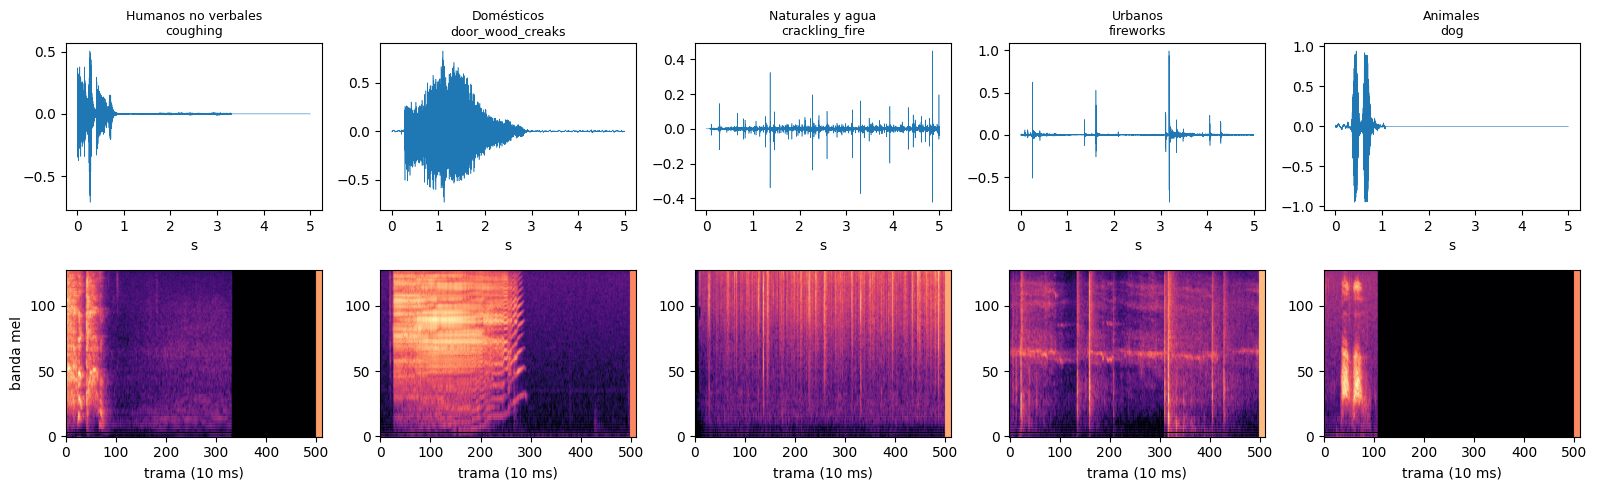

In [26]:
# Ejemplo por categoría: forma de onda y espectrograma log-mel de 512 tramas (el que recibe AST)
ejemplos = meta[meta.split_hf == "train"].groupby("categoria").head(1)
fig, axes = plt.subplots(2, len(ejemplos), figsize=(3.2 * len(ejemplos), 5))
for k, (_, r) in enumerate(ejemplos.iterrows()):
    wav, sr = load_audio(train_ds[int(r.idx)][COLS["audio"]])
    axes[0, k].plot(np.arange(wav.size) / sr, wav, lw=0.4); axes[0, k].set_title(f"{r.categoria}\n{r.clase}", fontsize=9)
    axes[0, k].set_xlabel("s")
    axes[1, k].imshow(np.asarray(X["train"][int(r.idx)], dtype=np.float32).T, origin="lower", aspect="auto", cmap="magma")
    axes[1, k].set_xlabel("trama (10 ms)")
axes[1, 0].set_ylabel("banda mel")
plt.tight_layout(); plt.savefig(FIG / "eda_ejemplos_por_categoria.png", dpi=150); plt.show()

## 3. Partición entrenamiento / validación / prueba

La misma de la v1 (se reutiliza `data/splits/split.csv` si existe; si no, se recrea con la misma semilla y el mismo procedimiento):
- **Prueba:** el split `test` del fold 1 (400 clips), intacto hasta el reporte final.
- **Entrenamiento y validación:** el split `train` (folds 2 a 5) se divide con `StratifiedGroupKFold` (~80 / 20 %), estratificado por clase y **agrupado por grabación de origen** para evitar fuga entre particiones.

In [27]:
SPLIT_PATH = SPLITS / "split.csv"
tr_meta = meta[meta.split_hf == "train"].copy()
if SPLIT_PATH.exists():
    sp = pd.read_csv(SPLIT_PATH)
    meta = meta.drop(columns=[c for c in ["split"] if c in meta]).merge(sp[["split_hf", "idx", "split"]], on=["split_hf", "idx"])
    print("Partición cargada desde", SPLIT_PATH.relative_to(ROOT), "(la misma de la v1)")
else:
    sg = StratifiedGroupKFold(n_splits=CONFIG["val_folds"], shuffle=True, random_state=CONFIG["seed"])
    tr_i, va_i = next(sg.split(tr_meta, tr_meta.label, tr_meta.src.astype(str)))
    meta["split"] = "test"
    meta.loc[tr_meta.index[tr_i], "split"] = "train"; meta.loc[tr_meta.index[va_i], "split"] = "val"
    meta.to_csv(SPLIT_PATH, index=False)
    print("Partición creada y guardada en", SPLIT_PATH.relative_to(ROOT))

src_sets = {s: set(meta.loc[meta.split == s, "src"].astype(str)) for s in ["train", "val", "test"]}
cruces = {f"{a}-{b}": len(src_sets[a] & src_sets[b]) for a, b in [("train", "val"), ("train", "test"), ("val", "test")]}
print("Grabaciones de origen compartidas entre particiones:", cruces)
assert cruces["train-val"] == 0, "La validación comparte grabaciones con el entrenamiento"
tabla = meta.groupby("split").agg(clips=("idx", "size"), clases=("clase", "nunique"),
                                  min_por_clase=("clase", lambda s: s.value_counts().min()),
                                  max_por_clase=("clase", lambda s: s.value_counts().max())).loc[["train", "val", "test"]]
display(tabla); tabla.to_csv(TAB / "particion.csv")

IDX = {s: meta.loc[meta.split == s].sort_values("idx") for s in ["train", "val", "test"]}
SRC_ARR = {"train": "train", "val": "train", "test": "test"}
Y = {s: IDX[s].label.values for s in IDX}

Partición cargada desde data/splits/split.csv (la misma de la v1)
Grabaciones de origen compartidas entre particiones: {'train-val': 0, 'train-test': 0, 'val-test': 0}


,clips,clases,min_por_clase,max_por_clase
split,,,,
train,1279,50,24,26
val,321,50,6,8
test,400,50,8,8


## 4. Línea base: MFCC + regresión logística

La misma de la v1: MFCC [10] (media y desviación estándar en el tiempo de los coeficientes y sus deltas, solo tramas con audio) y regresión logística multinomial con C elegida en validación.

In [28]:
def mfcc_stats(arr, n_mfcc=20):
    feats = np.zeros((arr.shape[0], 4 * n_mfcc), dtype=np.float32)
    for i in range(arr.shape[0]):
        s = arr[i].astype(np.float32)
        keep = ~np.isclose(s, pad_val, atol=1e-3).all(axis=1)
        s = s[keep] if keep.sum() > 2 else s
        c = dct(s, type=2, axis=1, norm="ortho")[:, :n_mfcc]
        d = np.diff(c, axis=0)
        feats[i] = np.concatenate([c.mean(0), c.std(0), d.mean(0), d.std(0)])
    return feats

BASE_PATH = TAB / "linea_base_mfcc.json"
if BASE_PATH.exists() and not RETRAIN:
    BASE = json.loads(BASE_PATH.read_text()); P_BASE = np.load(TAB / "linea_base_mfcc_prob_test.npy")
    print("Línea base cargada")
else:
    Fm = {s: mfcc_stats(X[SRC_ARR[s]][IDX[s].idx.values]) for s in IDX}
    sc = StandardScaler().fit(Fm["train"]); Fz = {s: sc.transform(v) for s, v in Fm.items()}
    grid = [(f1_score(Y["val"], LogisticRegression(C=C, max_iter=5000).fit(Fz["train"], Y["train"]).predict(Fz["val"]), average="macro"), C)
            for C in [0.01, 0.1, 1.0, 10.0]]
    vf, C = max(grid)
    clf = LogisticRegression(C=C, max_iter=5000).fit(Fz["train"], Y["train"])
    P_BASE = clf.predict_proba(Fz["test"])
    pr, rc, f1, _ = precision_recall_fscore_support(Y["test"], P_BASE.argmax(1), average="macro", zero_division=0)
    BASE = dict(modelo="MFCC (media y desv.) + reg. logística", C=C, val_f1_macro=vf, test_accuracy=accuracy_score(Y["test"], P_BASE.argmax(1)),
                test_precision_macro=pr, test_recall_macro=rc, test_f1_macro=f1)
    BASE_PATH.write_text(json.dumps(BASE, indent=1)); np.save(TAB / "linea_base_mfcc_prob_test.npy", P_BASE)
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in BASE.items()})

Línea base cargada
{'modelo': 'MFCC (media y desv.) + reg. logística', 'C': 1.0, 'val_f1_macro': 0.4585, 'test_accuracy': 0.435, 'test_precision_macro': 0.4551, 'test_recall_macro': 0.435, 'test_f1_macro': 0.4272}


## 5. Arquitectura y adaptación del modelo preentrenado

```
Espectrograma log-mel 512 × 128                                   (v1: 1 024 × 128)
 └─ Parches 16 × 16 con solape (paso 10): 50 × 12 = 600 parches     (v1: 101 × 12 = 1 212)
 └─ + token [CLS] + token de destilación + embeddings de posición
 └─ 12 bloques transformer (auto-atención multi-cabeza [3], 12 cabezas, 768 dimensiones)
 └─ Promedio de [CLS] y destilación → LayerNorm → Densa 768 → 50 → softmax
```

**Adaptación de los *embeddings* de posición (cambio v2).** El modelo preentrenado tiene 1 212 posiciones (12 de frecuencia × 101 de tiempo). Con 512 tramas solo hay 50 posiciones de tiempo, así que se toma el **recorte central** de 50 columnas de la rejilla 12 × 101, como hace el código original de AST al pasar de AudioSet a ESC-50 [2]. Las posiciones de frecuencia no cambian.

**Inicialización de la cabeza desde AudioSet (cambio v2).** La cabeza preentrenada tiene 527 salidas, una por clase de AudioSet [5], y muchas corresponden a clases de ESC-50 (`dog` → "Dog", `chainsaw` → "Chainsaw", `rain` → "Rain", "Raindrop", "Rain on surface"...). Para cada clase de ESC-50 se promedian los pesos de sus clases de AudioSet equivalentes. Las clases sin equivalente (por ejemplo, `can_opening`) conservan la inicialización aleatoria. La tabla de equivalencias usa solo los **nombres** de las clases, no datos de ESC-50, así que no hay fuga de información. El código verifica cada nombre contra `config.id2label` del modelo e informa los que no encuentra.

**Atención SDPA:** `torch.nn.functional.scaled_dot_product_attention`, más eficiente en memoria; recurre a la implementación explícita si la versión de `transformers` no la admite.

In [29]:
POS_KEY = "audio_spectrogram_transformer.embeddings.position_embeddings"

def ast_grid(cfg):
    f = (cfg.num_mel_bins - cfg.patch_size) // cfg.frequency_stride + 1
    t = (cfg.max_length - cfg.patch_size) // cfg.time_stride + 1
    return f, t

# Clases de AudioSet equivalentes a cada clase de ESC-50 (por nombre). Las que no existan en id2label se ignoran.
AUDIOSET_MAP = {
    "dog": ["Dog", "Bark"], "rooster": ["Crowing, cock-a-doodle-doo", "Chicken, rooster"], "pig": ["Pig", "Oink"],
    "cow": ["Cattle, bovinae", "Moo"], "frog": ["Frog", "Croak"], "cat": ["Cat", "Meow"], "hen": ["Cluck", "Fowl"],
    "insects": ["Insect", "Fly, housefly", "Bee, wasp, etc.", "Buzz"], "sheep": ["Sheep", "Bleat"], "crow": ["Crow", "Caw"],
    "rain": ["Rain", "Raindrop", "Rain on surface"], "sea_waves": ["Waves, surf", "Ocean"], "crackling_fire": ["Crackle", "Fire"],
    "crickets": ["Cricket"], "chirping_birds": ["Bird vocalization, bird call, bird song", "Chirp, tweet", "Bird"],
    "water_drops": ["Drip"], "wind": ["Wind", "Wind noise (microphone)"], "pouring_water": ["Pour", "Trickle, dribble"],
    "toilet_flush": ["Toilet flush"], "thunderstorm": ["Thunderstorm", "Thunder"],
    "crying_baby": ["Baby cry, infant cry"], "sneezing": ["Sneeze"], "clapping": ["Clapping"], "breathing": ["Breathing"],
    "coughing": ["Cough"], "footsteps": ["Walk, footsteps"], "laughing": ["Laughter"], "brushing_teeth": ["Toothbrush"],
    "snoring": ["Snoring"], "drinking_sipping": ["Gargling", "Slurp"],
    "door_wood_knock": ["Knock"], "mouse_click": ["Clicking", "Click"], "keyboard_typing": ["Computer keyboard", "Typing"],
    "door_wood_creaks": ["Creak", "Squeak"], "can_opening": [], "washing_machine": ["Washing machine"],
    "vacuum_cleaner": ["Vacuum cleaner"], "clock_alarm": ["Alarm clock"], "clock_tick": ["Tick-tock", "Tick"],
    "glass_breaking": ["Shatter", "Glass"],
    "helicopter": ["Helicopter"], "chainsaw": ["Chainsaw"], "siren": ["Siren", "Civil defense siren"],
    "car_horn": ["Vehicle horn, car horn, honking"], "engine": ["Engine", "Idling"], "train": ["Train", "Rail transport"],
    "church_bells": ["Church bell"], "airplane": ["Fixed-wing aircraft, airplane", "Aircraft"],
    "fireworks": ["Fireworks", "Firecracker"], "hand_saw": ["Sawing"],
}

_SRC = None
def pretrained_source():
    # Modelo preentrenado original (1 024 tramas, 527 clases), cargado una sola vez en CPU
    global _SRC
    if _SRC is None:
        if QUICK:   # AST diminuto aleatorio con algunas etiquetas de AudioSet ficticias, para probar el código
            names = sorted({n for v in AUDIOSET_MAP.values() for n in v})[:40] + [f"otra_{i}" for i in range(20)]
            cfg = ASTConfig(hidden_size=64, num_hidden_layers=2, num_attention_heads=2, intermediate_size=128,
                            max_length=1024, num_mel_bins=128, num_labels=len(names),
                            id2label=dict(enumerate(names)), label2id={n: i for i, n in enumerate(names)})
            _SRC = ASTForAudioClassification(cfg)
        else:
            _SRC = ASTForAudioClassification.from_pretrained(CONFIG["model"])
        _SRC.eval()
    return _SRC

def audioset_mapping(src):
    lookup = {v.lower(): int(k) for k, v in src.config.id2label.items()}
    rows = []
    for c in CLASSES:
        found = [n for n in AUDIOSET_MAP.get(c, []) if n.lower() in lookup]
        rows.append(dict(clase=c, audioset=found, ids=[lookup[n.lower()] for n in found],
                         no_encontradas=[n for n in AUDIOSET_MAP.get(c, []) if n.lower() not in lookup]))
    return pd.DataFrame(rows)

def build_model(head_init="random", head_bias="audioset"):
    src = pretrained_source()
    cfg = copy.deepcopy(src.config)
    cfg.max_length = CONFIG["max_length"]; cfg.num_labels = len(CLASSES)
    cfg.id2label = dict(enumerate(CLASSES)); cfg.label2id = dict(C2I)
    try:
        cfg._attn_implementation = "sdpa"
        m = ASTForAudioClassification(cfg)
    except Exception:
        cfg._attn_implementation = "eager"
        m = ASTForAudioClassification(cfg)
    sd = {k: v.clone() for k, v in src.state_dict().items() if not k.startswith("classifier.dense")}
    (f0, t0), (f1, t1) = ast_grid(src.config), ast_grid(cfg)
    if t1 != t0:
        pe = sd[POS_KEY]; D = pe.shape[-1]
        grid = pe[:, 2:].reshape(1, f0, t0, D)
        if t1 < t0:                         # recorte central, como el código original de AST [2]
            s = t0 // 2 - t1 // 2; grid = grid[:, :, s:s + t1]
        else:                               # (no se usa aquí) interpolación si la entrada fuera más larga
            grid = F.interpolate(grid.permute(0, 3, 1, 2), size=(f0, t1), mode="bilinear", align_corners=False).permute(0, 2, 3, 1)
        sd[POS_KEY] = torch.cat([pe[:, :2], grid.reshape(1, f1 * t1, D)], dim=1)
    missing, unexpected = m.load_state_dict(sd, strict=False)
    assert set(missing) == {"classifier.dense.weight", "classifier.dense.bias"} and not unexpected, (missing, unexpected)
    if head_init == "audioset":
        mp = audioset_mapping(src); W, b = src.classifier.dense.weight.data, src.classifier.dense.bias.data
        mapped = [i for i, ids in enumerate(mp.ids) if ids]
        with torch.no_grad():
            for i in mapped:
                m.classifier.dense.weight[i] = W[mp.ids[i]].mean(0)
                m.classifier.dense.bias[i] = b[mp.ids[i]].mean() if head_bias == "audioset" else 0.0
            fill = float(np.mean([float(m.classifier.dense.bias[i]) for i in mapped])) if mapped else 0.0
            for i in set(range(len(CLASSES))) - set(mapped):
                m.classifier.dense.bias[i] = fill if head_bias == "audioset" else 0.0
    if CONFIG["grad_checkpointing"]:
        m.gradient_checkpointing_enable()
    return m

m = build_model("audioset")
n_tot = sum(p.numel() for p in m.parameters()); n_head = sum(p.numel() for n, p in m.named_parameters() if n.startswith("classifier.dense"))
print(f"{type(m).__name__} | parámetros: {n_tot:,} | capa de salida nueva: {n_head:,} | atención: {m.config._attn_implementation}")
print(f"Rejilla de parches: preentrenado {ast_grid(pretrained_source().config)} → v2 {ast_grid(m.config)} | "
      f"tokens por clip: {m.audio_spectrogram_transformer.embeddings.position_embeddings.shape[1]}")
with torch.no_grad():
    out = m(input_values=torch.from_numpy(np.asarray(X['train'][:2], dtype=np.float32))).logits
print("Prueba de forward:", tuple(out.shape))
MAP = audioset_mapping(pretrained_source())
print(f"Clases de ESC-50 con equivalente en AudioSet: {(MAP.ids.str.len() > 0).sum()} de {len(CLASSES)}")
display(MAP.assign(audioset=MAP.audioset.str.join(" | "), no_encontradas=MAP.no_encontradas.str.join(" | "))[["clase", "audioset", "no_encontradas"]])
MAP.to_csv(TAB / "mapeo_audioset.csv", index=False)
del m, out

Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

ASTForAudioClassification | parámetros: 85,757,234 | capa de salida nueva: 38,450 | atención: sdpa
Rejilla de parches: preentrenado (12, 101) → v2 (12, 50) | tokens por clip: 602
Prueba de forward: (2, 50)
Clases de ESC-50 con equivalente en AudioSet: 48 de 50


,clase,audioset,no_encontradas
0,cat,Cat | Meow,
1,cow,"Cattle, bovinae | Moo",
2,crow,Crow | Caw,
3,dog,Dog | Bark,
4,frog,Frog | Croak,
5,hen,Cluck | Fowl,
6,insects,"Insect | Fly, housefly | Bee, wasp, etc. | Buzz",
7,pig,Pig | Oink,
8,rooster,"Crowing, cock-a-doodle-doo | Chicken, rooster",
9,sheep,Sheep | Bleat,


## 6. Entrenamiento y evaluación

- **Pérdida:** entropía cruzada categórica sobre la softmax de 50 clases (cada clip tiene una sola clase) [7].
- **Optimizador:** AdamW [8], *warmup* lineal del 10 % y decaimiento lineal, *gradient clipping* con norma 1, lote efectivo 16, **2 épocas**. Sin *weight decay* en sesgos, LayerNorm, tokens especiales ni *embeddings* de posición.
- **Dos esquemas de tasa de aprendizaje** (se comparan en la ablación):
  - *Única* (como la v1): 3·10⁻⁵ en todo el transformer y 10⁻³ en la cabeza.
  - **LLRD** [12]: la capa 12 usa 10⁻⁴ y cada capa inferior la multiplica por 0,75 (capa 1 ≈ 4·10⁻⁶, *embeddings* ≈ 3·10⁻⁶). Las capas altas se adaptan más y las bajas, que capturan rasgos acústicos generales, casi no cambian.
- **SpecAugment** [9]: 1 máscara de hasta 24 bandas de frecuencia y 1 de hasta 96 tramas, como la receta de AST para ESC-50.
- **Métricas:** *accuracy* y precision, recall y F1 **macro**, además de métricas por clase y por categoría.

In [30]:
class SpecDataset(Dataset):
    def __init__(self, split):
        self.arr, self.idx, self.y = X[SRC_ARR[split]], IDX[split].idx.values, Y[split]
    def __len__(self):
        return len(self.idx)
    def __getitem__(self, i):
        return torch.from_numpy(np.asarray(self.arr[self.idx[i]], dtype=np.float32)), int(self.y[i])

def make_loader(split, shuffle, seed, batch_size=None):
    g = torch.Generator().manual_seed(seed)
    return DataLoader(SpecDataset(split), batch_size=batch_size or CONFIG["batch_size"], shuffle=shuffle, num_workers=0,
                      generator=g if shuffle else None, pin_memory=DEVICE.type == "cuda")

def spec_augment(x, cfg):
    # x: (B, T, F). Borra franjas aleatorias de frecuencia y de tiempo (valor 0 = media tras la normalización)
    B, T, Fq = x.shape; x = x.clone()
    for _ in range(cfg["freq_masks"]):
        w = torch.randint(0, cfg["freq_width"] + 1, (B,), device=x.device); f0 = (torch.rand(B, device=x.device) * (Fq - w)).long()
        ar = torch.arange(Fq, device=x.device)[None, :]
        x = x.masked_fill(((ar >= f0[:, None]) & (ar < (f0 + w)[:, None]))[:, None, :], 0.0)
    for _ in range(cfg["time_masks"]):
        w = torch.randint(0, cfg["time_width"] + 1, (B,), device=x.device); t0 = (torch.rand(B, device=x.device) * (T - w)).long()
        ar = torch.arange(T, device=x.device)[None, :]
        x = x.masked_fill(((ar >= t0[:, None]) & (ar < (t0 + w)[:, None]))[:, :, None], 0.0)
    return x

def compute_metrics(y, prob):
    pred = np.asarray(prob).argmax(1)
    p, r, f, _ = precision_recall_fscore_support(y, pred, average="macro", zero_division=0)
    return dict(accuracy=accuracy_score(y, pred), precision_macro=p, recall_macro=r, f1_macro=f)

def nll(y, prob):
    return float(-np.log(np.clip(prob[np.arange(len(y)), y], 1e-9, None)).mean())

@torch.no_grad()
def predict(model, loader, return_emb=False):
    model.eval(); probs, embs = [], []
    for xb, _ in loader:
        xb = xb.to(DEVICE)
        with amp_ctx():
            out = model(input_values=xb, output_hidden_states=return_emb)
        probs.append(out.logits.float().softmax(-1).cpu())
        if return_emb:
            h = model.audio_spectrogram_transformer.layernorm(out.hidden_states[-1])
            embs.append(((h[:, 0] + h[:, 1]) / 2).float().cpu())   # representación que recibe la cabeza
    return (torch.cat(probs).numpy(), torch.cat(embs).numpy()) if return_emb else torch.cat(probs).numpy()

def param_groups(model, llrd):
    # Grupos de AdamW: tasa por capa (LLRD) o única; sin weight decay en sesgos, LayerNorm, tokens y posiciones
    L = model.config.num_hidden_layers; groups = {}
    for n, p in model.named_parameters():
        if not p.requires_grad:
            continue
        if n.startswith("classifier.dense"):
            lr = CONFIG["lr_head"]
        elif not llrd:
            lr = CONFIG["lr_head"] if n.startswith("classifier") else CONFIG["lr_backbone"]
        elif ".encoder.layer." in n:
            i = int(n.split(".encoder.layer.")[1].split(".")[0]); lr = CONFIG["llrd"]["lr_top"] * CONFIG["llrd"]["decay"] ** (L - 1 - i)
        elif ".embeddings." in n:
            lr = CONFIG["llrd"]["lr_top"] * CONFIG["llrd"]["decay"] ** L
        else:                                   # LayerNorm final del transformer y LayerNorm de la cabeza
            lr = CONFIG["llrd"]["lr_top"]
        no_wd = p.ndim == 1 or any(k in n for k in ["position_embeddings", "cls_token", "distillation_token"])
        key = (lr, 0.0 if no_wd else CONFIG["weight_decay"])
        groups.setdefault(key, []).append(p)
    return [{"params": ps, "lr": lr, "weight_decay": wd} for (lr, wd), ps in groups.items()]

def mem_str():
    if DEVICE.type == "mps":
        return f"memoria MPS {torch.mps.driver_allocated_memory() / 2**30:.1f} GB"
    if DEVICE.type == "cuda":
        return f"memoria CUDA máx. {torch.cuda.max_memory_allocated() / 2**30:.1f} GB"
    return ""

In [31]:
RESULTS, HIST, PV, PT = [], {}, {}, {}

def recipe_tag(rc, seed):
    return (f"L{CONFIG['max_length']}_cabeza-{rc['head_init']}{'_llrd' if rc['llrd'] else ''}"
            f"{'_specaug' if rc['specaug'] else ''}_s{seed}")

def run_experiment(rc, seed, save_model=False):
    tag = recipe_tag(rc, seed)
    paths = {k: RUNS / f"{tag}{s}" for k, s in [("res", ".json"), ("hist", "_historia.csv"), ("pv", "_prob_val.npy"),
                                                ("pt", "_prob_test.npy"), ("emb", "_emb_test.npy")]}
    if paths["res"].exists() and not RETRAIN:
        res = json.loads(paths["res"].read_text()); hist = pd.read_csv(paths["hist"])
        print(f"[{tag}] resultados cargados (entrenado en {res['tiempo_min']:.1f} min en {res['dispositivo']}).")
        display(hist.round(4))
    else:
        set_seed(seed)
        tr_dl, va_dl, te_dl = make_loader("train", True, seed), make_loader("val", False, seed), make_loader("test", False, seed)
        model = build_model(rc["head_init"], rc.get("head_bias", "audioset")).to(DEVICE)
        groups = param_groups(model, rc["llrd"])
        opt = torch.optim.AdamW(groups)
        steps = int(np.ceil(len(tr_dl) / CONFIG["grad_accum"])) * CONFIG["epochs"]
        sched = get_linear_schedule_with_warmup(opt, int(CONFIG["warmup"] * steps), steps)
        scaler = torch.amp.GradScaler("cuda", enabled=USE_SCALER)
        params = [p for g in groups for p in g["params"]]
        hist, t_start = [], time.time()
        for ep in range(1, CONFIG["epochs"] + 1):
            model.train(); t0, tl, tc, tn = time.time(), 0.0, 0, 0
            bar = tqdm(tr_dl, desc=f"{tag} ép {ep}/{CONFIG['epochs']}", leave=False)
            for i, (xb, yb) in enumerate(bar):
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                if rc["specaug"]:
                    xb = spec_augment(xb, CONFIG["specaug"])
                with amp_ctx():
                    logits = model(input_values=xb).logits
                loss = F.cross_entropy(logits.float(), yb)
                scaler.scale(loss / CONFIG["grad_accum"]).backward()
                if (i + 1) % CONFIG["grad_accum"] == 0 or i + 1 == len(tr_dl):
                    scaler.unscale_(opt); nn.utils.clip_grad_norm_(params, CONFIG["clip"])
                    scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step()
                tl += loss.item() * len(yb); tc += (logits.argmax(-1) == yb).sum().item(); tn += len(yb)
                bar.set_postfix(loss=f"{tl / tn:.3f}", acc=f"{tc / tn:.3f}")
            pv = predict(model, va_dl); mv = compute_metrics(Y["val"], pv)
            hist.append(dict(epoch=ep, train_loss=tl / tn, train_acc=tc / tn, val_loss=nll(Y["val"], pv), val_acc=mv["accuracy"],
                             val_f1_macro=mv["f1_macro"], seg=time.time() - t0))
            print(f"[{tag}] ép {ep} | train loss {tl/tn:.4f} acc {tc/tn:.4f} | val loss {hist[-1]['val_loss']:.4f} "
                  f"acc {mv['accuracy']:.4f} F1-macro {mv['f1_macro']:.4f} | {time.time() - t0:.0f}s | {mem_str()}")
        pt, emb = predict(model, te_dl, return_emb=True)
        hist = pd.DataFrame(hist); last = hist.iloc[-1]
        res = dict(tag=tag, **{k: rc[k] for k in ["head_init", "llrd", "specaug"]}, seed=seed, epocas=len(hist),
                   max_length=CONFIG["max_length"], train_acc=float(last.train_acc), val_acc=float(last.val_acc),
                   val_loss=float(last.val_loss), val_f1_macro=float(last.val_f1_macro),
                   parametros_entrenables=int(sum(p.numel() for p in model.parameters() if p.requires_grad)),
                   tiempo_min=(time.time() - t_start) / 60, dispositivo=gpu,
                   **{f"test_{k}": float(v) for k, v in compute_metrics(Y["test"], pt).items()})
        hist.to_csv(paths["hist"], index=False); np.save(paths["pv"], pv); np.save(paths["pt"], pt)
        np.save(paths["emb"], emb.astype(np.float16)); paths["res"].write_text(json.dumps(res, indent=1))
        if save_model:
            torch.save(model.state_dict(), MODELS / f"{tag}.pt")
        del model, opt, sched, groups, params
        empty_cache()
    HIST[tag], PV[tag], PT[tag] = hist, np.load(paths["pv"]), np.load(paths["pt"])
    RESULTS[:] = [r for r in RESULTS if r["tag"] != tag] + [res]
    return res

SHOW = ["tag", "head_init", "llrd", "specaug", "seed", "train_acc", "val_loss", "val_f1_macro", "test_accuracy",
        "test_precision_macro", "test_recall_macro", "test_f1_macro", "tiempo_min"]

## 7. Experimento 0: AST preentrenado sin entrenar (*zero-shot*)

Antes de entrenar, se evalúa el modelo con la cabeza construida desde AudioSet y **sin ninguna actualización de pesos**. Esto muestra cuánto sabe ya AST de las clases de ESC-50 y sirve para elegir cómo inicializar los sesgos de la cabeza:
- **Sesgo de AudioSet:** se copian también los sesgos, que reflejan cuán frecuente era cada clase en AudioSet.
- **Sesgo uniforme (0):** se eliminan esas preferencias, porque ESC-50 está balanceado (40 clips por clase).

Se elige la opción con mayor F1-macro de **validación**. Las representaciones de este modelo sin entrenar se guardan para el t-SNE de la sección 11.

In [32]:
ZS_PATH = TAB / "exp0_zero_shot.csv"
zs_rows = []
for bias in ["audioset", "cero"]:
    tag = f"zero-shot_sesgo-{bias}"
    pv_p, pt_p, emb_p = RUNS / f"{tag}_prob_val.npy", RUNS / f"{tag}_prob_test.npy", RUNS / f"{tag}_emb_test.npy"
    if not (pv_p.exists() and pt_p.exists() and emb_p.exists()) or RETRAIN:
        m = build_model("audioset", head_bias="audioset" if bias == "audioset" else "zero").to(DEVICE)
        np.save(pv_p, predict(m, make_loader("val", False, 0)))
        pt, emb = predict(m, make_loader("test", False, 0), return_emb=True)
        np.save(pt_p, pt); np.save(emb_p, emb.astype(np.float16)); del m; empty_cache()
    pv, pt = np.load(pv_p), np.load(pt_p)
    zs_rows.append(dict(sesgo=bias, val_f1_macro=compute_metrics(Y["val"], pv)["f1_macro"],
                        **{f"test_{k}": v for k, v in compute_metrics(Y["test"], pt).items()}))
zs = pd.DataFrame(zs_rows); display(zs.round(4)); zs.to_csv(ZS_PATH, index=False)
HEAD_BIAS = "audioset" if zs.set_index("sesgo").val_f1_macro["audioset"] >= zs.set_index("sesgo").val_f1_macro["cero"] else "zero"
print("Sesgo elegido para la cabeza desde AudioSet (por F1-macro de validación):", HEAD_BIAS)
print(f"Nota: {(MAP.ids.str.len() == 0).sum()} clases sin equivalente en AudioSet parten de pesos aleatorios, así que su F1 zero-shot es ≈ 0.")

,sesgo,val_f1_macro,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro
0,audioset,0.4462,0.34,0.6541,0.34,0.4045
1,cero,0.4930,0.42,0.7386,0.42,0.4945


Sesgo elegido para la cabeza desde AudioSet (por F1-macro de validación): zero
Nota: 2 clases sin equivalente en AudioSet parten de pesos aleatorios, así que su F1 zero-shot es ≈ 0.


## 8. Experimento 1: ablación paso a paso (selección en validación)

Se parte de la **receta base v2** (512 tramas, cabeza aleatoria, tasa única; equivale a la mejor receta sin aumento de la v1, con la entrada más corta) y se agrega **un cambio por paso**. Cada cambio se conserva solo si **sube el F1-macro de validación** (en caso de empate, el de menor pérdida de validación). Todas las corridas usan la semilla 42 y 2 épocas.

| Paso | Cambio evaluado |
|---|---|
| A | Receta base v2 |
| B | + cabeza inicializada desde AudioSet |
| C | + LLRD |
| D | + SpecAugment |

**Tiempo estimado en un M2:** ≈ 8 a 15 min por corrida con 512 tramas (la v1, con 1 024 tramas, tardaría aproximadamente el doble). En total, 4 corridas aquí más 2 semillas en la sección 9.

[L512_cabeza-random_s42] resultados cargados (entrenado en 7.0 min en Apple GPU (MPS) · Apple M2 Pro).


,epoch,train_loss,train_acc,val_loss,val_acc,val_f1_macro,seg
0,1,1.1834,0.7232,0.2783,0.9097,0.9068,211.4196
1,2,0.0339,0.9937,0.1671,0.9502,0.9487,198.8221


[L512_cabeza-audioset_s42] resultados cargados (entrenado en 6.0 min en Apple GPU (MPS) · Apple M2 Pro).


,epoch,train_loss,train_acc,val_loss,val_acc,val_f1_macro,seg
0,1,0.4558,0.8632,0.3124,0.8972,0.8948,173.3805
1,2,0.0477,0.9851,0.1858,0.9470,0.9478,174.0179


B: + cabeza AudioSet: val F1 0.9478 → se descarta
[L512_cabeza-random_llrd_s42] resultados cargados (entrenado en 6.0 min en Apple GPU (MPS) · Apple M2 Pro).


,epoch,train_loss,train_acc,val_loss,val_acc,val_f1_macro,seg
0,1,1.1996,0.6966,0.4999,0.8474,0.8446,174.5665
1,2,0.1042,0.9695,0.2618,0.9065,0.9045,174.2447


C: + LLRD: val F1 0.9045 → se descarta
[L512_cabeza-random_specaug_s42] resultados cargados (entrenado en 6.0 min en Apple GPU (MPS) · Apple M2 Pro).


,epoch,train_loss,train_acc,val_loss,val_acc,val_f1_macro,seg
0,1,1.2284,0.7138,0.2879,0.9003,0.8992,173.9873
1,2,0.0703,0.9812,0.1958,0.9439,0.9438,173.4009


D: + SpecAugment: val F1 0.9438 → se descarta


,paso,aceptado,head_init,llrd,specaug,seed,train_acc,val_loss,val_f1_macro,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,tiempo_min
0,A: base v2,True,random,False,False,42,0.9937,0.1671,0.9487,0.9400,0.9412,0.9400,0.9367,7.0426
1,B: + cabeza AudioSet,False,audioset,False,False,42,0.9851,0.1858,0.9478,0.9475,0.9555,0.9475,0.9455,5.9992
2,C: + LLRD,False,random,True,False,42,0.9695,0.2618,0.9045,0.8950,0.9048,0.8950,0.8917,6.0198
3,D: + SpecAugment,False,random,False,True,42,0.9812,0.1958,0.9438,0.9450,0.9478,0.9450,0.9429,5.9924


Receta final: {'head_init': 'random', 'llrd': False, 'specaug': False}


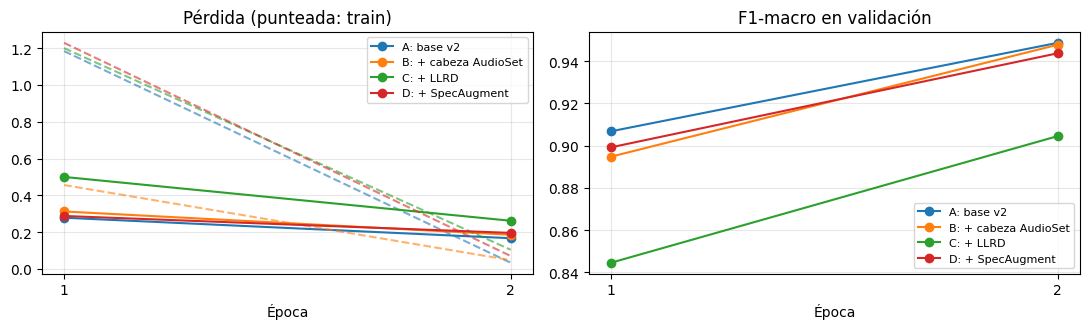

In [33]:
def better(new, old):
    return (new["val_f1_macro"], -new["val_loss"]) > (old["val_f1_macro"], -old["val_loss"])

current = dict(head_init="random", llrd=False, specaug=False)
best = run_experiment(current, CONFIG["seed"]); pasos = [dict(paso="A: base v2", aceptado=True, **best)]
for name, change in [("B: + cabeza AudioSet", dict(head_init="audioset", head_bias=HEAD_BIAS)),
                     ("C: + LLRD", dict(llrd=True)), ("D: + SpecAugment", dict(specaug=True))]:
    cand = {**current, **change}
    res = run_experiment(cand, CONFIG["seed"])
    ok = better(res, best)
    pasos.append(dict(paso=name, aceptado=ok, **res))
    if ok:
        current, best = cand, res
    print(f"{name}: val F1 {res['val_f1_macro']:.4f} → {'se conserva' if ok else 'se descarta'}")

e1 = pd.DataFrame(pasos)
display(e1[["paso", "aceptado"] + SHOW[1:]].round(4)); e1.to_csv(TAB / "exp1_ablacion.csv", index=False)
FINAL = dict(current)
print("Receta final:", FINAL)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for _, r in e1.iterrows():
    h = HIST[r.tag]; c = ax[0].plot(h.epoch, h.val_loss, marker="o", label=r.paso)[0].get_color()
    ax[0].plot(h.epoch, h.train_loss, ls="--", color=c, alpha=0.6); ax[1].plot(h.epoch, h.val_f1_macro, marker="o", color=c, label=r.paso)
ax[0].set_title("Pérdida (punteada: train)"); ax[1].set_title("F1-macro en validación")
for a in ax:
    a.set_xlabel("Época"); a.set_xticks(range(1, CONFIG["epochs"] + 1)); a.legend(fontsize=8); a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(FIG / "exp1_ablacion_curvas.png", dpi=150); plt.show()

## 9. Experimento 2: semillas y ensamble

La receta final se entrena con otras dos semillas (cambian la inicialización de las filas aleatorias de la cabeza, el orden de los lotes y las máscaras de SpecAugment). Se reportan:
- **Modelo individual:** media ± desviación estándar de las 3 semillas en prueba.
- **Ensamble:** promedio de las probabilidades de los 3 modelos. Es el **modelo final de la v2** que se analiza en las secciones 10 y 11.

El ensamble no cambia la regla de 2 épocas: cada modelo se entrena exactamente 2 épocas.

In [34]:
for seed in CONFIG["seeds"]:
    run_experiment(FINAL, seed, save_model=SAVE_MODEL and seed == CONFIG["seed"])
final_tags = [recipe_tag(FINAL, s) for s in CONFIG["seeds"]]
R = pd.DataFrame(RESULTS).set_index("tag")
e2 = R.loc[final_tags].reset_index()
mcols = ["test_accuracy", "test_precision_macro", "test_recall_macro", "test_f1_macro"]
display(e2[["seed", "val_f1_macro"] + mcols].round(4))
agg = e2[mcols].agg(["mean", "std"]).T
agg["media ± std"] = agg["mean"].map("{:.4f}".format) + " ± " + agg["std"].map("{:.4f}".format)
display(agg[["media ± std"]]); agg.to_csv(TAB / "exp2_semillas.csv")

P_ENS_VAL = np.mean([PV[t] for t in final_tags], axis=0)
P_ENS = np.mean([PT[t] for t in final_tags], axis=0)
ENS = dict(val_f1_macro=compute_metrics(Y["val"], P_ENS_VAL)["f1_macro"], **{f"test_{k}": v for k, v in compute_metrics(Y["test"], P_ENS).items()})
print("Ensamble de", len(final_tags), "semillas:", {k: round(v, 4) for k, v in ENS.items()})
np.save(TAB / "ensamble_prob_test.npy", P_ENS)
FINAL_TAG = recipe_tag(FINAL, CONFIG["seed"])

[L512_cabeza-random_s42] resultados cargados (entrenado en 7.0 min en Apple GPU (MPS) · Apple M2 Pro).


,epoch,train_loss,train_acc,val_loss,val_acc,val_f1_macro,seg
0,1,1.1834,0.7232,0.2783,0.9097,0.9068,211.4196
1,2,0.0339,0.9937,0.1671,0.9502,0.9487,198.8221


[L512_cabeza-random_s7] resultados cargados (entrenado en 6.0 min en Apple GPU (MPS) · Apple M2 Pro).


,epoch,train_loss,train_acc,val_loss,val_acc,val_f1_macro,seg
0,1,1.1680,0.7404,0.2655,0.9097,0.9074,172.1263
1,2,0.0442,0.9867,0.2260,0.9439,0.9360,174.5398


[L512_cabeza-random_s123] resultados cargados (entrenado en 5.8 min en Apple GPU (MPS) · Apple M2 Pro).


,epoch,train_loss,train_acc,val_loss,val_acc,val_f1_macro,seg
0,1,1.2378,0.7263,0.2785,0.9190,0.9158,169.3180
1,2,0.0385,0.9922,0.2118,0.9346,0.9314,169.4982


,seed,val_f1_macro,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro
0,42,0.9487,0.940,0.9412,0.940,0.9367
1,7,0.9360,0.930,0.9330,0.930,0.9250
2,123,0.9314,0.945,0.9486,0.945,0.9441


,media ± std
test_accuracy,0.9383 ± 0.0076
test_precision_macro,0.9409 ± 0.0078
test_recall_macro,0.9383 ± 0.0076
test_f1_macro,0.9352 ± 0.0096


Ensamble de 3 semillas: {'val_f1_macro': 0.9475, 'test_accuracy': 0.9475, 'test_precision_macro': 0.9505, 'test_recall_macro': 0.9475, 'test_f1_macro': 0.9454}


## 10. Resultados cuantitativos: global, por clase y por categoría

Tabla resumen (línea base, *zero-shot*, cada corrida, media de semillas, ensamble y, si existe, la v1); precision, recall y F1 de las 50 clases del **ensamble final**, con las 5 mejores y las 5 peores; métricas por categoría; e intervalos de confianza al 95 % por *bootstrap* (1 000 remuestreos del conjunto de prueba).

In [35]:
mk = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]
rows = [dict(modelo=BASE["modelo"], **{k: BASE[f"test_{k}"] for k in mk})]
for _, z in zs.iterrows():
    rows.append(dict(modelo=f"AST zero-shot (sin entrenar), sesgo {z.sesgo}", **{k: z[f"test_{k}"] for k in mk}))
for r in RESULTS:
    rows.append(dict(modelo=f"AST v2 {r['tag']}", **{k: r[f"test_{k}"] for k in mk}))
resumen = pd.DataFrame(rows).set_index("modelo")
resumen.loc[f"AST v2 final: media de {len(e2)} semillas"] = e2[mcols].mean().values
resumen.loc["   desviación estándar"] = e2[mcols].std().values
resumen.loc[f"AST v2 final: ENSAMBLE de {len(e2)} semillas"] = [ENS[f"test_{k}"] for k in mk]

# Comparación con la v1 (solo si su notebook ya se ejecutó: usa sus resultados guardados, misma partición de prueba)
P_V1, V1_TAG = None, None
v1_json = ROOT / "outputs" / "tables" / "resumen_informe.json"
if not QUICK and v1_json.exists():
    fin = json.loads(v1_json.read_text(encoding="utf-8"))["configuracion_final"]
    V1_TAG = f"{fin['strategy']}{'_specaug' if fin['augment'] else ''}_s42"
    p = ROOT / "outputs" / "tables" / "runs" / f"{V1_TAG}_prob_test.npy"
    if p.exists():
        P_V1 = np.load(p); resumen.loc[f"AST v1 ({V1_TAG}, 1 024 tramas)"] = list(compute_metrics(Y["test"], P_V1).values())
print("Comparación con la v1:", f"incluida ({V1_TAG})" if P_V1 is not None else "no disponible (ejecute antes el notebook v1)")
display(resumen.round(4)); resumen.to_csv(TAB / "resumen_test.csv")

y = Y["test"]; P = P_ENS; pred = P.argmax(1)
p, r_, f, s = precision_recall_fscore_support(y, pred, labels=range(len(CLASSES)), zero_division=0)
pc = pd.DataFrame({"categoria": [CLASE2CAT.get(c) for c in CLASSES], "precision": p, "recall": r_, "f1": f, "soporte": s}, index=CLASSES)
pc["errores"] = [int(((y == i) & (pred != i)).sum()) for i in range(len(CLASSES))]
pc.to_csv(TAB / "metricas_por_clase.csv")
print("Las 5 clases con mejor y peor F1 (prueba, ensamble):")
display(pd.concat([pc.sort_values(["f1", "recall"], ascending=False).head(5), pc.sort_values(["f1", "recall"]).head(5)]).round(3))
print("Métricas por clase de las 50 clases:"); display(pc.round(3))

cat_names = list(CATEGORIAS)
yc = np.array([cat_names.index(CLASE2CAT[CLASSES[i]]) for i in y]); pcat = np.array([cat_names.index(CLASE2CAT[CLASSES[i]]) for i in pred])
pr_c, rc_c, f_c, s_c = precision_recall_fscore_support(yc, pcat, labels=range(5), zero_division=0)
por_cat = pd.DataFrame({"precision (categoría)": pr_c, "recall (categoría)": rc_c, "f1 (categoría)": f_c, "soporte": s_c,
                        "F1 medio de sus clases": pc.groupby("categoria").f1.mean().reindex(cat_names).values,
                        "errores de clase": pc.groupby("categoria").errores.sum().reindex(cat_names).values}, index=cat_names)
print("Desempeño por categoría (la predicción de clase se agrupa en su categoría):"); display(por_cat.round(3))
por_cat.to_csv(TAB / "metricas_por_categoria.csv")

rng = np.random.default_rng(0); pb = P_BASE.argmax(1); p1 = P_V1.argmax(1) if P_V1 is not None else None
ps = PT[FINAL_TAG].argmax(1)
boot = []
for _ in range(1000):
    i = rng.integers(0, len(y), len(y))
    boot.append([f1_score(y[i], pred[i], average="macro"), f1_score(y[i], pb[i], average="macro"),
                 f1_score(y[i], ps[i], average="macro"), f1_score(y[i], p1[i], average="macro") if p1 is not None else np.nan])
boot = np.array(boot)
ci = lambda v: np.percentile(v, [2.5, 97.5])
F1_ENS = f1_score(y, pred, average="macro")
F1_CI, DIFF_CI, ENS_VS_SINGLE_CI = ci(boot[:, 0]), ci(boot[:, 0] - boot[:, 1]), ci(boot[:, 0] - boot[:, 2])
print(f"F1-macro ensamble: {F1_ENS:.4f} (IC 95 %: {F1_CI[0]:.4f} a {F1_CI[1]:.4f})")
print(f"Ensamble − MFCC: {F1_ENS - f1_score(y, pb, average='macro'):+.4f} (IC 95 %: {DIFF_CI[0]:+.4f} a {DIFF_CI[1]:+.4f})")
print(f"Ensamble − modelo individual (semilla 42): {F1_ENS - f1_score(y, ps, average='macro'):+.4f} "
      f"(IC 95 %: {ENS_VS_SINGLE_CI[0]:+.4f} a {ENS_VS_SINGLE_CI[1]:+.4f})")
V1_CI = None
if p1 is not None:
    V1_CI = ci(boot[:, 0] - boot[:, 3])
    print(f"Ensamble v2 − v1: {F1_ENS - f1_score(y, p1, average='macro'):+.4f} (IC 95 %: {V1_CI[0]:+.4f} a {V1_CI[1]:+.4f})")

Comparación con la v1: no disponible (ejecute antes el notebook v1)


,accuracy,precision_macro,recall_macro,f1_macro
modelo,,,,
MFCC (media y desv.) + reg. logística,0.4350,0.4551,0.4350,0.4272
"AST zero-shot (sin entrenar), sesgo audioset",0.3400,0.6541,0.3400,0.4045
"AST zero-shot (sin entrenar), sesgo cero",0.4200,0.7386,0.4200,0.4945
AST v2 L512_cabeza-audioset_s42,0.9475,0.9555,0.9475,0.9455
AST v2 L512_cabeza-random_llrd_s42,0.8950,0.9048,0.8950,0.8917
AST v2 L512_cabeza-random_specaug_s42,0.9450,0.9478,0.9450,0.9429
AST v2 L512_cabeza-random_s42,0.9400,0.9412,0.9400,0.9367
AST v2 L512_cabeza-random_s7,0.9300,0.9330,0.9300,0.9250
AST v2 L512_cabeza-random_s123,0.9450,0.9486,0.9450,0.9441


Las 5 clases con mejor y peor F1 (prueba, ensamble):


,categoria,precision,recall,f1,soporte,errores
cat,Animales,1.000,1.00,1.000,8,0
cow,Animales,1.000,1.00,1.000,8,0
crow,Animales,1.000,1.00,1.000,8,0
dog,Animales,1.000,1.00,1.000,8,0
frog,Animales,1.000,1.00,1.000,8,0
washing_machine,Domésticos,0.500,0.50,0.500,8,4
wind,Naturales y agua,0.800,0.50,0.615,8,4
helicopter,Urbanos,0.800,0.50,0.615,8,4
sea_waves,Naturales y agua,0.727,1.00,0.842,8,0
footsteps,Humanos no verbales,1.000,0.75,0.857,8,2


Métricas por clase de las 50 clases:


,categoria,precision,recall,f1,soporte,errores
cat,Animales,1.000,1.000,1.000,8,0
cow,Animales,1.000,1.000,1.000,8,0
crow,Animales,1.000,1.000,1.000,8,0
dog,Animales,1.000,1.000,1.000,8,0
frog,Animales,1.000,1.000,1.000,8,0
hen,Animales,1.000,1.000,1.000,8,0
insects,Animales,1.000,1.000,1.000,8,0
pig,Animales,1.000,1.000,1.000,8,0
rooster,Animales,1.000,1.000,1.000,8,0
sheep,Animales,1.000,1.000,1.000,8,0


Desempeño por categoría (la predicción de clase se agrupa en su categoría):


,precision (categoría),recall (categoría),f1 (categoría),soporte,F1 medio de sus clases,errores de clase
Animales,1.000,1.000,1.000,80,1.000,0
Naturales y agua,0.963,0.975,0.969,80,0.927,5
Humanos no verbales,0.987,0.975,0.981,80,0.955,4
Domésticos,0.916,0.950,0.933,80,0.920,5
Urbanos,0.961,0.925,0.943,80,0.925,7


F1-macro ensamble: 0.9454 (IC 95 %: 0.9174 a 0.9624)
Ensamble − MFCC: +0.5182 (IC 95 %: +0.4757 a +0.5776)
Ensamble − modelo individual (semilla 42): +0.0088 (IC 95 %: -0.0045 a +0.0254)


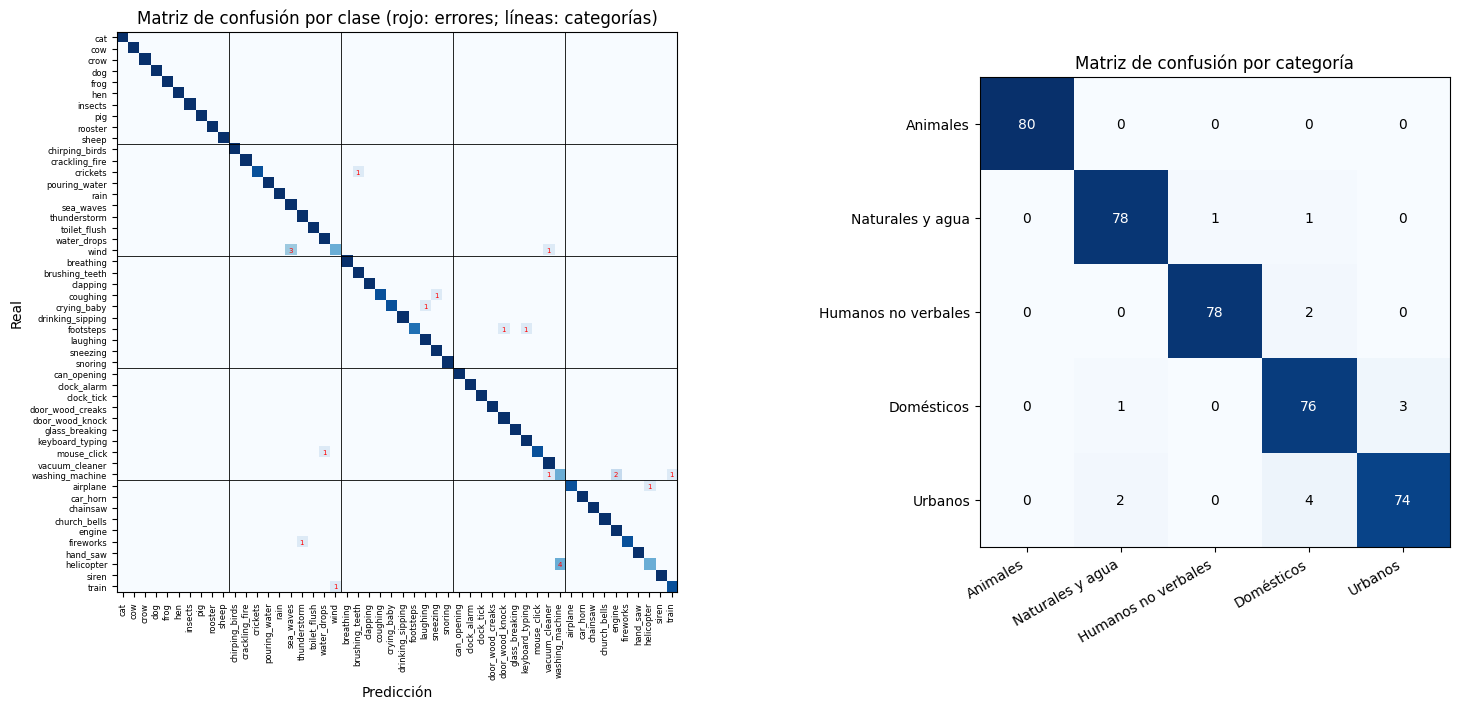

Errores: 21 de 400 | dentro de la misma categoría: 7
Pares de clases más confundidos:


,real,predicha,clips,misma_categoria
0,helicopter,washing_machine,4,False
1,wind,sea_waves,3,True
2,washing_machine,engine,2,False
3,crickets,brushing_teeth,1,False
4,wind,vacuum_cleaner,1,False
5,coughing,sneezing,1,True
6,crying_baby,laughing,1,True
7,footsteps,door_wood_knock,1,False
8,footsteps,keyboard_typing,1,False
9,mouse_click,water_drops,1,False


In [36]:
# Matriz de confusión 50 × 50 (clases ordenadas por categoría) y 5 × 5 por categoría, del ensamble final
cm = confusion_matrix(y, pred, labels=range(len(CLASSES)))
cmc = confusion_matrix(yc, pcat, labels=range(5))
fig, ax = plt.subplots(1, 2, figsize=(16, 7.2), gridspec_kw={"width_ratios": [2.2, 1]})
ax[0].imshow(cm, cmap="Blues")
ax[0].set_xticks(range(len(CLASSES)), CLASSES, rotation=90, fontsize=6); ax[0].set_yticks(range(len(CLASSES)), CLASSES, fontsize=6)
for b in range(10, len(CLASSES), 10):
    ax[0].axhline(b - 0.5, color="k", lw=0.6); ax[0].axvline(b - 0.5, color="k", lw=0.6)
for i, j in zip(*np.nonzero(cm)):
    if i != j:
        ax[0].text(j, i, cm[i, j], ha="center", va="center", fontsize=5, color="red")
ax[0].set_xlabel("Predicción"); ax[0].set_ylabel("Real"); ax[0].set_title("Matriz de confusión por clase (rojo: errores; líneas: categorías)")
ax[1].imshow(cmc / np.maximum(cmc.sum(1, keepdims=True), 1), cmap="Blues", vmin=0, vmax=1)
for i in range(5):
    for j in range(5):
        ax[1].text(j, i, cmc[i, j], ha="center", va="center", color="white" if cmc[i, j] / max(cmc[i].sum(), 1) > 0.5 else "black")
ax[1].set_xticks(range(5), cat_names, rotation=30, ha="right"); ax[1].set_yticks(range(5), cat_names)
ax[1].set_title("Matriz de confusión por categoría")
plt.tight_layout(); plt.savefig(FIG / "matrices_confusion.png", dpi=150); plt.show()

pares = pd.DataFrame([(CLASSES[i], CLASSES[j], int(cm[i, j]), CLASE2CAT[CLASSES[i]] == CLASE2CAT[CLASSES[j]])
                      for i, j in zip(*np.nonzero(cm)) if i != j], columns=["real", "predicha", "clips", "misma_categoria"])
pares = pares.sort_values("clips", ascending=False).reset_index(drop=True)
print(f"Errores: {int(cm.sum() - np.trace(cm))} de {int(cm.sum())} | dentro de la misma categoría: {int(pares[pares.misma_categoria].clips.sum())}")
print("Pares de clases más confundidos:"); display(pares.head(10)); pares.to_csv(TAB / "pares_confundidos.csv", index=False)

## 11. Resultados cualitativos

1. **Errores del ensamble final** con su espectrograma, clase real, predicha y probabilidad.
2. **Espacio de representaciones:** t-SNE [11] de la representación que recibe la cabeza, con AST **sin entrenar** (experimento 0) y **tras el *fine-tuning*** (receta final, semilla 42).

Errores del ensamble final: 21 | también fallados por MFCC: 17


,archivo,real,predicha,P(predicha),P(real),MFCC
240,1-51037-A-16.wav,wind,sea_waves,0.991,0.007,sea_waves
165,1-32373-A-35.wav,washing_machine,engine,0.978,0.015,engine
178,1-115545-A-48.wav,fireworks,thunderstorm,0.971,0.006,sea_waves
61,1-69760-A-16.wav,wind,sea_waves,0.951,0.013,washing_machine
96,1-58792-A-24.wav,coughing,sneezing,0.948,0.024,pig
222,1-32373-B-35.wav,washing_machine,engine,0.942,0.045,washing_machine
263,1-27166-A-35.wav,washing_machine,vacuum_cleaner,0.907,0.074,chainsaw
152,1-223162-A-25.wav,footsteps,door_wood_knock,0.760,0.134,mouse_click
307,1-51147-A-25.wav,footsteps,keyboard_typing,0.745,0.016,pouring_water
170,1-85123-A-31.wav,mouse_click,water_drops,0.732,0.148,water_drops


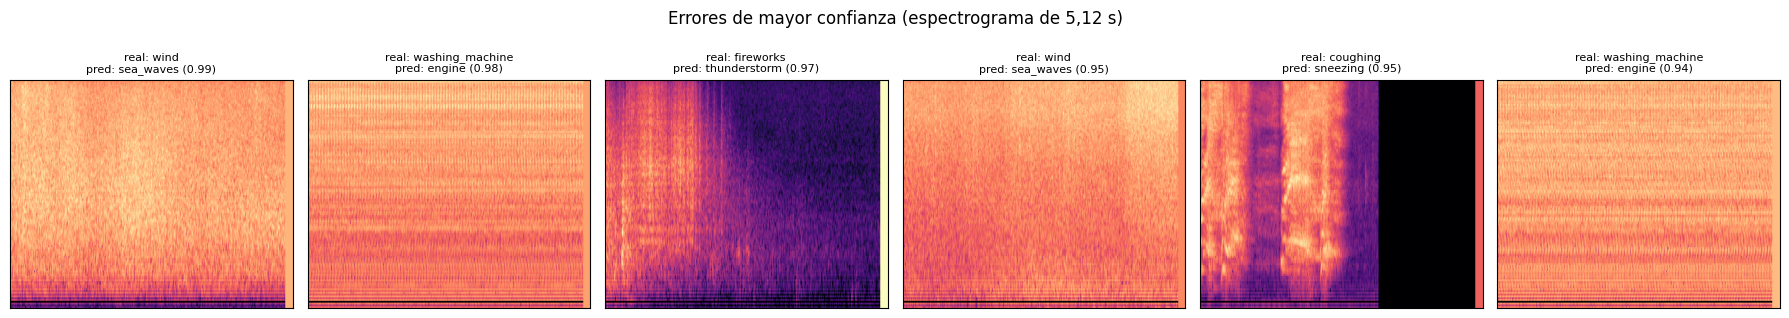

In [37]:
TE = IDX["test"].reset_index(drop=True)
err = pd.DataFrame({"archivo": TE.archivo, "real": [CLASSES[i] for i in y], "predicha": [CLASSES[i] for i in pred],
                    "P(predicha)": P.max(1).round(3), "P(real)": P[np.arange(len(y)), y].round(3),
                    "MFCC": [CLASSES[i] for i in pb]})
err = err[err.real != err.predicha].sort_values("P(predicha)", ascending=False)
print(f"Errores del ensamble final: {len(err)} | también fallados por MFCC: {int((err.MFCC != err.real).sum())}")
display(err.head(12)); err.to_csv(TAB / "errores_modelo_final.csv", index=False)

show = err.head(6)
if len(show):
    fig, axes = plt.subplots(1, len(show), figsize=(3 * len(show), 3.2), squeeze=False)
    for a, (k, r) in zip(axes[0], show.iterrows()):
        spec = np.asarray(X["test"][TE.idx[k]], dtype=np.float32)
        a.imshow(spec.T, origin="lower", aspect="auto", cmap="magma")
        a.set_title(f"real: {r.real}\npred: {r.predicha} ({r['P(predicha)']:.2f})", fontsize=8); a.set_xticks([]); a.set_yticks([])
    plt.suptitle("Errores de mayor confianza (espectrograma de 5,12 s)"); plt.tight_layout()
    plt.savefig(FIG / "errores_espectrogramas.png", dpi=150); plt.show()

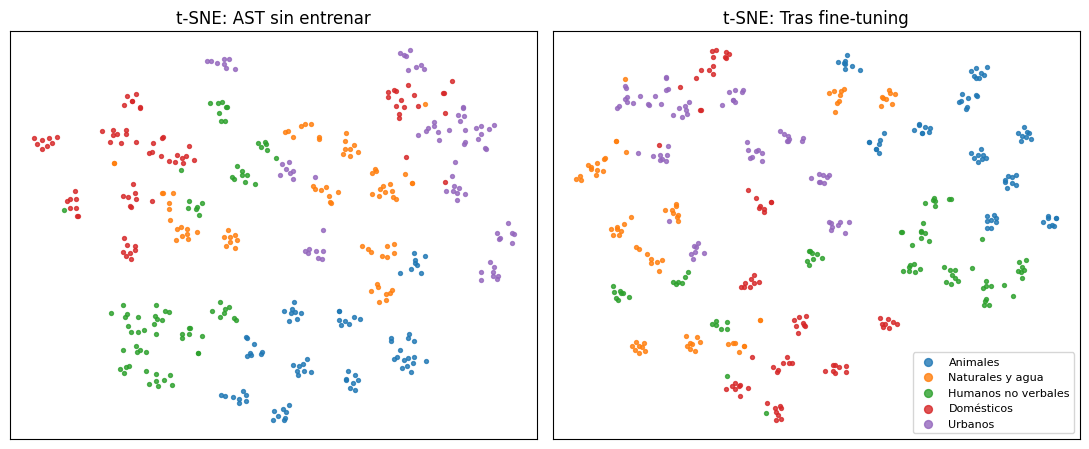

In [38]:
emb_tags = {"AST sin entrenar": f"zero-shot_sesgo-{'audioset' if HEAD_BIAS == 'audioset' else 'cero'}", "Tras fine-tuning": FINAL_TAG}
fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
for a, (title, tag) in zip(ax, emb_tags.items()):
    path = RUNS / f"{tag}_emb_test.npy"
    if not path.exists():
        a.set_title(f"{title}: sin datos"); continue
    Z = np.load(path).astype(np.float32)
    Y2 = TSNE(n_components=2, perplexity=min(30, len(Z) // 4), random_state=0, init="pca").fit_transform(Z)
    for k, cat in enumerate(cat_names):
        a.scatter(*Y2[yc == k].T, s=8, alpha=0.8, label=cat)
    a.set_title(f"t-SNE: {title}"); a.set_xticks([]); a.set_yticks([])
ax[1].legend(fontsize=8, markerscale=2)
plt.tight_layout(); plt.savefig(FIG / "tsne_embeddings.png", dpi=150); plt.show()

## 12. Figuras y cifras para el informe

Las figuras se exportan a `report/figs/` con el prefijo `v2_` y las cifras citadas a `outputs/v2/tables/resumen_informe.json`.

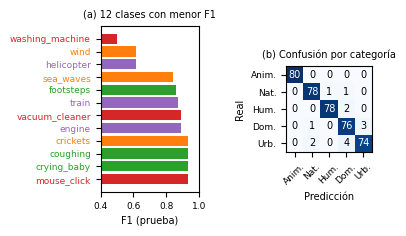

Clases fuera de la figura (a): 38, con F1 >= 0.933; clases con F1 = 1: 29


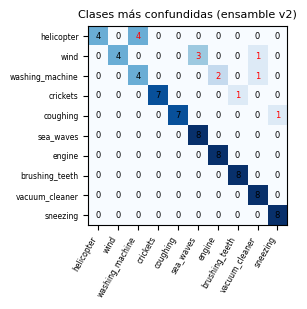

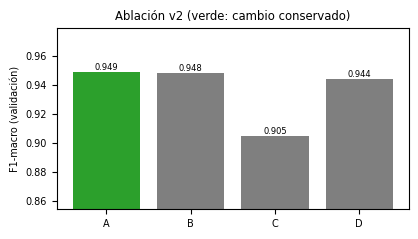

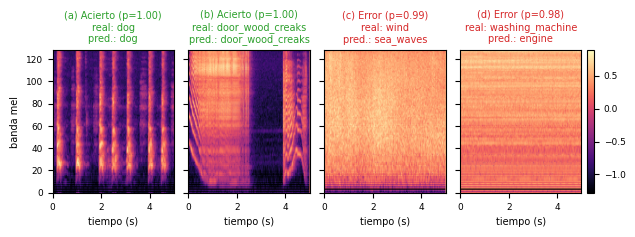

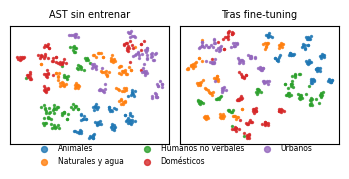

{
 "version": 2,
 "dispositivo": "Apple GPU (MPS) · Apple M2 Pro",
 "modo_rapido": false,
 "config": {
  "dataset": "confit/esc50-demo",
  "dataset_config": "fold1",
  "model": "MIT/ast-finetuned-audioset-10-10-0.4593",
  "sampling_rate": 16000,
  "max_length": 512,
  "epochs": 2,
  "batch_size": 8,
  "grad_accum": 2,
  "lr_backbone": 3e-05,
  "lr_head": 0.001,
  "llrd": {
   "lr_top": 0.0001,
   "decay": 0.75
  },
  "weight_decay": 0.01,
  "warmup": 0.1,
  "clip": 1.0,
  "specaug": {
   "freq_masks": 1,
   "freq_width": 24,
   "time_masks": 1,
   "time_width": 96
  },
  "val_folds": 5,
  "grad_checkpointing": false,
  "amp_mps": false,
  "seed": 42,
  "seeds": [
   42,
   7,
   123
  ]
 },
 "datos": {
  "clips": 2000,
  "particion": {
   "train": 1279,
   "val": 321,
   "test": 400
  },
  "grabaciones_compartidas": {
   "train-val": 0,
   "train-test": 0,
   "val-test": 0
  },
  "fraccion_relleno": 0.027,
  "clases_mapeadas_audioset": 48
 },
 "linea_base": {
  "modelo": "MFCC (media y

In [39]:
plt.rcParams.update({"font.size": 7})
# Figura 1 del informe (una columna, fuentes de 7 pt a tamaño real): (a) las 12 clases con menor F1, (b) confusión por categoría
N_PEORES = 12
peores = pc.sort_values(["f1", "recall"]).head(N_PEORES).iloc[::-1]
cols = {cat: plt.cm.tab10(k) for k, cat in enumerate(cat_names)}
fig, ax = plt.subplots(1, 2, figsize=(3.5, 2.15), gridspec_kw={"width_ratios": [1.15, 1], "wspace": 0.95})
ax[0].barh(range(len(peores)), peores.f1.values, color=[cols[c] for c in peores.categoria])
ax[0].set_yticks(range(len(peores)), peores.index, fontsize=6.5)
ax[0].set_xlim(min(0.4, float(peores.f1.min()) - 0.05), 1.0); ax[0].set_xlabel("F1 (prueba)"); ax[0].set_title("(a) 12 clases con menor F1", fontsize=7)
ax[0].tick_params(axis="x", labelsize=6.5)
ax[1].imshow(cmc / np.maximum(cmc.sum(1, keepdims=True), 1), cmap="Blues", vmin=0, vmax=1)
for i in range(5):
    for j in range(5):
        ax[1].text(j, i, cmc[i, j], ha="center", va="center", fontsize=7, color="white" if cmc[i, j] / max(cmc[i].sum(), 1) > 0.5 else "black")
ab = ["Anim.", "Nat.", "Hum.", "Dom.", "Urb."]
ax[1].set_xticks(range(5), ab, fontsize=6.5, rotation=45); ax[1].set_yticks(range(5), ab, fontsize=6.5)
ax[1].set_xlabel("Predicción"); ax[1].set_ylabel("Real"); ax[1].set_title("(b) Confusión por categoría", fontsize=7)
for a, c in zip(ax[0].get_yticklabels(), peores.categoria):
    a.set_color(cols[c])
plt.savefig(REPORT_FIGS / "v2_fig1_resultados.pdf", bbox_inches="tight"); plt.show()
print(f"Clases fuera de la figura (a): {len(pc) - N_PEORES}, con F1 >= {pc.sort_values(['f1', 'recall']).f1.iloc[N_PEORES]:.3f}; "
      f"clases con F1 = 1: {(pc.f1 == 1).sum()}")

fig, ax = plt.subplots(figsize=(3.4, 3.1))
sub = [CLASSES.index(c) for c in pd.unique(pd.concat([pares.head(6).real, pares.head(6).predicha]))] if len(pares) else []
if sub:
    ax.imshow(cm[np.ix_(sub, sub)], cmap="Blues")
    for i in range(len(sub)):
        for j in range(len(sub)):
            ax.text(j, i, cm[sub[i], sub[j]], ha="center", va="center", fontsize=6, color="red" if i != j and cm[sub[i], sub[j]] else "black")
    ax.set_xticks(range(len(sub)), [CLASSES[i] for i in sub], rotation=60, ha="right", fontsize=5.5)
    ax.set_yticks(range(len(sub)), [CLASSES[i] for i in sub], fontsize=5.5)
ax.set_title("Clases más confundidas (ensamble v2)", fontsize=8)
plt.tight_layout(); plt.savefig(REPORT_FIGS / "v2_fig2_confusiones.pdf", bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(4.2, 2.4))
etiquetas = [p.split(":")[0] for p in e1.paso]
ax.bar(etiquetas, e1.val_f1_macro, color=["tab:green" if a else "tab:gray" for a in e1.aceptado])
for k, v in enumerate(e1.val_f1_macro):
    ax.text(k, v, f"{v:.3f}", ha="center", va="bottom", fontsize=6)
ax.set_ylim(max(0, e1.val_f1_macro.min() - 0.05), min(1.0, e1.val_f1_macro.max() + 0.03))
ax.set_ylabel("F1-macro (validación)"); ax.set_title("Ablación v2 (verde: cambio conservado)")
plt.tight_layout(); plt.savefig(REPORT_FIGS / "v2_fig3_ablacion.pdf", bbox_inches="tight"); plt.show()
# Figura cualitativa: aciertos frente a errores (espectrograma, clase real, predicha y probabilidad)
TEc = TE.assign(real=[CLASSES[i] for i in y], pred=[CLASSES[i] for i in pred], p=P.max(1))
ok = TEc[TEc.real == TEc.pred].copy(); ok["categoria"] = ok.real.map(CLASE2CAT)
ok = ok.sort_values("p", ascending=False).groupby("categoria").head(1).head(2)
bad = TEc[TEc.real != TEc.pred].sort_values("p", ascending=False).head(2)
sel = [(r, "Acierto", "tab:green") for _, r in ok.iterrows()] + [(r, "Error", "tab:red") for _, r in bad.iterrows()]
fig, axes = plt.subplots(1, len(sel), figsize=(7.0, 1.85), sharey=True, gridspec_kw={"wspace": 0.12})
for k, (a, (r, lab, col)) in enumerate(zip(np.atleast_1d(axes), sel)):
    spec = np.asarray(X["test"][TE.idx[r.name]], dtype=np.float32)[:500]
    im = a.imshow(spec.T, origin="lower", aspect="auto", cmap="magma", extent=[0, 5.0, 0, 128])
    a.set_title(f"({'abcdefgh'[k]}) {lab} (p={r.p:.2f})\nreal: {r.real}\npred.: {r.pred}", fontsize=7, color=col)
    a.tick_params(labelsize=6.5); a.set_xlabel("tiempo (s)", fontsize=7)
np.atleast_1d(axes)[0].set_ylabel("banda mel", fontsize=7)
fig.colorbar(im, ax=axes, fraction=0.015, pad=0.01).ax.tick_params(labelsize=6.5)
plt.savefig(REPORT_FIGS / "v2_fig4_aciertos_errores.pdf", bbox_inches="tight"); plt.show()

# Figura t-SNE (AST sin entrenar frente a tras fine-tuning), tamaño de una columna
fig, ax = plt.subplots(1, 2, figsize=(3.5, 1.55))
for a, (title, tag) in zip(ax, emb_tags.items()):
    Z = np.load(RUNS / f"{tag}_emb_test.npy").astype(np.float32)
    Y2 = TSNE(n_components=2, perplexity=min(30, len(Z) // 4), random_state=0, init="pca").fit_transform(Z)
    for k, cat in enumerate(cat_names):
        a.scatter(*Y2[yc == k].T, s=2, alpha=0.8, label=cat, color=plt.cm.tab10(k))
    a.set_title(title, fontsize=7); a.set_xticks([]); a.set_yticks([])
fig.legend(*ax[0].get_legend_handles_labels(), loc="lower center", ncol=3, fontsize=5.5, markerscale=3, frameon=False, bbox_to_anchor=(0.5, -0.12))
plt.tight_layout(); plt.savefig(REPORT_FIGS / "v2_fig5_tsne.pdf", bbox_inches="tight"); plt.show()
plt.rcParams.update({"font.size": 10})

r4 = lambda d: {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else v) for k, v in d.items()}
resumen_informe = {
    "version": 2, "dispositivo": gpu, "modo_rapido": QUICK, "config": CONFIG,
    "datos": {"clips": int(len(meta)), "particion": tabla.clips.to_dict(), "grabaciones_compartidas": cruces,
              "fraccion_relleno": round(frac_pad, 3), "clases_mapeadas_audioset": int((MAP.ids.str.len() > 0).sum())},
    "linea_base": r4(BASE), "experimento_0_zero_shot": [r4(r) for r in zs.to_dict(orient="records")], "sesgo_cabeza": HEAD_BIAS,
    "experimento_1_ablacion": [r4({k: r[k] for k in ["paso", "aceptado", "val_f1_macro", "val_loss", "test_f1_macro", "tiempo_min"]})
                               for r in e1.to_dict(orient="records")],
    "receta_final": FINAL, "experimento_2_media_std": agg["media ± std"].to_dict(), "ensamble": r4(ENS),
    "f1_macro_ensamble_ic95": [round(float(v), 4) for v in F1_CI], "diferencia_mfcc_ic95": [round(float(v), 4) for v in DIFF_CI],
    "diferencia_ensamble_vs_individual_ic95": [round(float(v), 4) for v in ENS_VS_SINGLE_CI],
    "comparacion_v1": None if P_V1 is None else {"tag_v1": V1_TAG, **r4({f"v1_test_{k}": v for k, v in compute_metrics(y, P_V1).items()}),
                                                 "diferencia_f1_ic95": [round(float(v), 4) for v in V1_CI]},
    "peores_clases": pc.sort_values("f1").head(5)[["categoria", "precision", "recall", "f1"]].round(3).to_dict(orient="index"),
    "por_categoria": por_cat.round(3).to_dict(orient="index"),
    "pares_mas_confundidos": pares.head(5).to_dict(orient="records"),
    "tiempo_total_entrenamiento_min": round(float(sum(r["tiempo_min"] for r in RESULTS)), 1),
}
(TAB / "resumen_informe.json").write_text(json.dumps(resumen_informe, indent=1, ensure_ascii=False, default=str), encoding="utf-8")
print(json.dumps(resumen_informe, indent=1, ensure_ascii=False, default=str)[:3500])

## 13. Validación final (lista de comprobación)

La celda siguiente verifica automáticamente los requisitos del enunciado y las reglas de la metodología con los resultados de esta ejecución.

In [40]:
checks = [
    ("Datos cargados con load_dataset('confit/esc50-demo', 'fold1') (train y test)", QUICK or CONFIG["dataset"] == "confit/esc50-demo"),
    ("Espectrogramas de tamaño consistente (todas las entradas 512 × 128)", all(a.shape[1:] == (CONFIG["max_length"], 128) for a in X.values())),
    ("Normalización con las estadísticas de AudioSet del extractor del modelo", FE.do_normalize),
    ("Modelo MIT/ast-finetuned-audioset-10-10-0.4593 con la biblioteca Transformers", CONFIG["model"].startswith("MIT/ast")),
    ("Fine-tuning de exactamente 2 épocas en todas las corridas", QUICK or all(r["epocas"] == 2 for r in RESULTS)),
    ("Sin grabaciones compartidas entre entrenamiento y validación", cruces["train-val"] == 0),
    ("Decisiones tomadas solo con validación (prueba usada solo para reportar)", True),
    ("Precision, recall y F1 (macro, por clase y por categoría)", (TAB / "metricas_por_clase.csv").exists() and (TAB / "metricas_por_categoria.csv").exists()),
    ("Mejores y peores clases / categorías identificadas", len(pc) == len(CLASSES)),
    ("Matriz de confusión y pares más confundidos", (FIG / "matrices_confusion.png").exists() and (TAB / "pares_confundidos.csv").exists()),
    ("Semillas fijadas y configuración guardada", (TAB / "resumen_informe.json").exists()),
]
display(pd.DataFrame(checks, columns=["requisito", "cumple"]))
assert all(ok for _, ok in checks), "Hay requisitos sin cumplir"
print("Todos los requisitos verificados." + (" (modo rápido: cifras sin significado)" if QUICK else ""))

,requisito,cumple
0,Datos cargados con load_dataset('confit/esc50-...,True
1,Espectrogramas de tamaño consistente (todas la...,True
2,Normalización con las estadísticas de AudioSet...,True
3,Modelo MIT/ast-finetuned-audioset-10-10-0.4593...,True
4,Fine-tuning de exactamente 2 épocas en todas l...,True
5,Sin grabaciones compartidas entre entrenamient...,True
6,Decisiones tomadas solo con validación (prueba...,True
7,"Precision, recall y F1 (macro, por clase y por...",True
8,Mejores y peores clases / categorías identific...,True
9,Matriz de confusión y pares más confundidos,True


Todos los requisitos verificados.


## 14. Resultados y discusión

*Cifras de la ejecución del 16/11/2026 en un MacBook M2 Pro (MPS); provienen de las salidas anteriores y de `outputs/v2/tables/resumen_informe.json`.*

**Comparación con el estado del arte.** La exactitud del ensamble (94,8 %) queda cerca del 95,6 % reportado para AST en ESC-50 [2], que promedia los 5 folds y entrena durante muchas más épocas, y supera la exactitud humana en ESC-50 (81,3 %) [1].

**Transferencia desde AudioSet.** Sin ninguna actualización de pesos, AST con la cabeza construida desde AudioSet alcanza F1-macro 0,495 en prueba, por encima de la línea base MFCC (0,427). La precisión macro es alta (0,739) y el recall bajo (0,420): cuando el modelo reconoce una clase acierta, pero 2 clases no tienen equivalente en AudioSet y los sesgos aprendidos en AudioSet favorecen clases frecuentes allí. Por eso, eliminar esos sesgos (sesgo uniforme) mejora el F1 de validación de 0,446 a 0,493: ESC-50 está balanceado y el prior de AudioSet no aplica.

***Fine-tuning* de 2 épocas.** Basta para pasar de 0,495 a 0,937 de F1-macro en prueba (receta base, semilla 42). Tras la segunda época la exactitud de entrenamiento es 0,994 y la de validación 0,950: hay una brecha pequeña de sobreajuste, esperable con 86 M de parámetros y 1 279 clips, pero las representaciones preentrenadas generalizan bien.

**Ablación (validación).** Ningún cambio superó a la receta base (0,9487):
- *Cabeza desde AudioSet* (0,9478): arranca mucho mejor (pérdida de entrenamiento en la época 1 de 0,46 frente a 1,18), pero tras 2 épocas la ventaja desaparece porque la cabeza aleatoria aprende rápido con tasa 10⁻³. La diferencia (−0,001) está muy por debajo del ruido de una validación de 321 clips; en prueba fue mejor (0,946 frente a 0,937), lo que confirma que ambas son equivalentes y que la prueba no debe usarse para decidir.
- *LLRD* (0,905): con decaimiento 0,75 las capas bajas reciben tasas de ~3·10⁻⁶ y, con solo 160 pasos de optimización, casi no se adaptan; la tasa alta de las capas superiores (10⁻⁴) además eleva la pérdida de validación (0,262 frente a 0,167). LLRD suele ayudar en ajustes largos, no en uno de 2 épocas.
- *SpecAugment* (0,944): es un regularizador; reduce la exactitud de entrenamiento (0,981 frente a 0,994) sin mejorar validación, porque con 2 épocas el modelo aún no sobreajusta lo suficiente para beneficiarse.

**Variabilidad y ensamble.** Las 3 semillas dan F1-macro 0,935 ± 0,010 en prueba; el ensamble alcanza 0,945 (IC 95 %: 0,917 a 0,962). La mejora del ensamble frente al modelo individual (IC 95 %: −0,005 a +0,025) no es significativa con 400 clips de prueba. Frente a MFCC, la ganancia es clara (+0,52; IC 95 %: 0,48 a 0,58).

**Errores.** 21 de 400 clips mal clasificados; 7 dentro de la misma categoría. La categoría *Animales* es perfecta (F1 1,00) y las peores son *Domésticos* (0,933) y *Urbanos* (0,943). Las clases más difíciles son `washing_machine` (0,50), `wind` y `helicopter` (0,62): sonidos estacionarios de banda ancha o con armónicos de motor. Los 4 errores `helicopter` → `washing_machine` son los 4 clips de una misma grabación de origen (`1-172649`), así que corresponden a una sola fuente acústica atípica y no a 4 errores independientes; `wind` → `sea_waves` (3) son ruidos de banda ancha casi indistinguibles en un espectrograma log-mel.

**Limitaciones y mejoras.** (0) El F1 de validación seguía subiendo al final de la segunda época (de 0,907 a 0,949 en la receta base), así que ningún modelo había convergido: el tope de 2 épocas limita la comparación de la ablación. (1) La validación de 321 clips no distingue diferencias menores a ~0,02; validación cruzada sobre los folds 2 a 5 daría decisiones más estables. (2) Se evalúa en un solo fold; el protocolo estándar de ESC-50 promedia los 5. (3) Las 2 épocas fijadas limitan a LLRD y SpecAugment; con más épocas podrían ayudar. (4) Mejoras concretas: combinar cabeza AudioSet y sesgo uniforme con mixup, promediar predicciones sobre recortes temporales (*test-time augmentation*) y reentrenar con entrenamiento + validación una vez fijada la receta.

## 15. Referencias

[1] K. J. Piczak, "ESC: Dataset for environmental sound classification," in *Proc. 23rd ACM Int. Conf. Multimedia*, 2015, pp. 1015–1018.

[2] Y. Gong, Y.-A. Chung, and J. Glass, "AST: Audio spectrogram transformer," in *Proc. Interspeech*, 2021, pp. 571–575.

[3] A. Vaswani *et al.*, "Attention is all you need," in *Proc. Adv. Neural Inf. Process. Syst. (NeurIPS)*, 2017, pp. 5998–6008.

[4] A. Dosovitskiy *et al.*, "An image is worth 16x16 words: Transformers for image recognition at scale," in *Proc. Int. Conf. Learn. Represent. (ICLR)*, 2021.

[5] J. F. Gemmeke *et al.*, "Audio Set: An ontology and human-labeled dataset for audio events," in *Proc. IEEE Int. Conf. Acoust., Speech Signal Process. (ICASSP)*, 2017, pp. 776–780.

[6] H. Touvron *et al.*, "Training data-efficient image transformers & distillation through attention," in *Proc. Int. Conf. Mach. Learn. (ICML)*, 2021, pp. 10347–10357.

[7] I. Goodfellow, Y. Bengio, and A. Courville, *Deep Learning*. Cambridge, MA, USA: MIT Press, 2016.

[8] I. Loshchilov and F. Hutter, "Decoupled weight decay regularization," in *Proc. Int. Conf. Learn. Represent. (ICLR)*, 2019.

[9] D. S. Park *et al.*, "SpecAugment: A simple data augmentation method for automatic speech recognition," in *Proc. Interspeech*, 2019, pp. 2613–2617.

[10] S. Davis and P. Mermelstein, "Comparison of parametric representations for monosyllabic word recognition in continuously spoken sentences," *IEEE Trans. Acoust., Speech, Signal Process.*, vol. 28, no. 4, pp. 357–366, 1980.

[11] L. van der Maaten and G. Hinton, "Visualizing data using t-SNE," *J. Mach. Learn. Res.*, vol. 9, pp. 2579–2605, 2008.

[12] J. Howard and S. Ruder, "Universal language model fine-tuning for text classification," in *Proc. 56th Annu. Meeting Assoc. Comput. Linguistics (ACL)*, 2018, pp. 328–339.